# CSE 438 - Assignment 01
## Group Information
| Field | Details |
|----------------------------|----------------------------------------------|
| **Group ID** | Group B |
| **Student 1 Name** | Nasrullah Kaisher Sijan |
| **Student 1 ID** | 2023-1-60-204 |
| **Student 2 Name** | G M MOTA-TAHRIN TAYEF |
| **Student 2 ID** | 2022-1-60-109 |
| **Student 3 Name** | Bushra Tahsin |
| **Student 3 ID** | 2023-3-60-129 |
| **Notebook Type** | Data Preprocesssing (Tasks B-D) |
| **Assignment 01 Best Acc** | Semantic Segmentation Model Benchmark-ing |
| **Dataset Name (Kaggle)** | /kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset |
| **Dataset Source** | Pixel-wise Annotation for Clear and Contaminated Regions Segmentation in Wireless Capsule Endoscopy Images: Kvasir capsule endoscopy |
| **Dataset Source Link** | https://data.mendeley.com/datasets/vmxhn95j8z/3 |
| **Submission Date** | 14 July 2026 |

# Kvasir Capsule Endoscopy Segmentation — Data Preprocessing (Tasks B–D)

**Scope of this notebook.** Task A (Exploratory Data Analysis) has already
been completed in a separate notebook (`capsule-endoscopy-for-gastroenterology.ipynb`).
This notebook does **not** repeat that analysis. It covers only:

| Task | Description |
|---|---|
| **Task B** | Leakage-safe data splitting (train / validation / test) |
| **Task C** | Data augmentation design + a reusable PyTorch dataset pipeline |
| **Task D** | Sanity-check visualization and automated quality-control validation |

Every preprocessing decision below is explicitly justified against the
findings already established in Task A (see the recap immediately below).
This notebook is designed to run **top to bottom** after only the
`DATASET_ROOT` path is set in the Configuration cell, and it produces every
artefact (`.csv`, `.json`, `.txt`, `.png`) that the downstream model-training
(Task E) and evaluation (Task F) notebooks will consume — so that no
preprocessing logic is ever repeated in this project.

## Recap of Completed EDA Findings (Task A)

The table below restates — **without recomputation** — the findings already
established in the Task A notebook. These findings are treated as fixed
inputs that drive every decision made in Tasks B–D.

| Finding | Result | Consequence for this notebook |
|---|---|---|
| Dataset integrity | 15,143 valid image–mask pairs; 0 corrupted images/masks; 0 missing pairs; 0 dimension mismatches | No further cleaning; every valid sample is preserved |
| Image resolution | 336 × 336 px for every image and mask | Native resolution is preserved; **no resizing** is performed |
| Pixel-level class balance (Binary GT) | Clear = 94.48%, Contaminated = 5.52% (imbalance ≈ 17.12 : 1) | The imbalance is **not** corrected by sampling; it is left for the loss function chosen in Task E |
| Image quality | Illumination, brightness and contrast variation; very few blurry images | Augmentation targets photometric robustness (brightness/contrast/illumination), with only mild, low-probability blur |
| Duplicates | Dataset originates from capsule video → many near-identical consecutive frames are expected | Similar frames are **not** removed; leakage-safety is instead handled explicitly in Task B |
| Cleanliness labels | Image-level metadata (not a segmentation class) | Used only for optional stratification, never rebalanced |

These figures are stored as constants (`EDA_FINDINGS`, defined in the
Configuration cell) so that every later justification, report, and metadata
file references the same, single source of truth rather than re-deriving it.

# CSE 438 - Assignment 01
## Group Information
| Field | Details |
|----------------------------|----------------------------------------------|
| **Group ID** | Group B |
| **Student 1 Name** | Nasrullah Kaisher Sijan |
| **Student 1 ID** | 2023-1-60-204 |
| **Student 2 Name** | G M MOTA-TAHRIN TAYEF |
| **Student 2 ID** | 2022-1-60-109 |
| **Student 3 Name** | Bushra Tahsin |
| **Student 3 ID** | 2023-3-60-129 |
| **Notebook Type** | Data Preprocessing (Tasks B–D) Notebook |
| **Assignment 01 Best Acc** | Semantic Segmentation Model Benchmark-ing |
| **Dataset Name (Kaggle)** | /kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset |
| **Dataset Source** | Pixel-wise Annotation for Clear and Contaminated Regions Segmentation in Wireless Capsule Endoscopy Images: Kvasir capsule endoscopy |
| **Dataset Source Link** | https://data.mendeley.com/datasets/vmxhn95j8z/3 |
| **Submission Date** | 14 July 2026 |

## Global Configuration

Every user-editable parameter lives in the single cell below. No other cell
in this notebook should need to be edited to reproduce the preprocessing
pipeline on a fresh copy of the dataset — only `DATASET_ROOT` must be set.

In [1]:
# ============================================================================
# GLOBAL CONFIGURATION -- the only cell that should need editing
# ============================================================================
from pathlib import Path

# --- REQUIRED: point this at the Kvasir dataset root -----------------------
# Expected layout:
#   <DATASET_ROOT>/Images/
#   <DATASET_ROOT>/Binary GT/
#   <DATASET_ROOT>/Tri-color GT/
#   <DATASET_ROOT>/Score.xlsx
DATASET_ROOT = Path(
    "/kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset"
)

# --- Dataset sub-folder / file names ----------------------------------------
# The EDA notebook found these to be the *actual* on-disk names. Directory
# lookup below is nonetheless fuzzy (case/whitespace/hyphen-insensitive) so
# this notebook tolerates minor naming differences on other machines.
IMAGES_DIRNAME = "Images"
BINARY_MASK_DIRNAME = "Binary GT"
TRICOLOR_MASK_DIRNAME = "Tri-color GT"
SCORE_FILENAME = "Score.xlsx"

IMAGE_DIR = DATASET_ROOT / IMAGES_DIRNAME
BINARY_MASK_DIR = DATASET_ROOT / BINARY_MASK_DIRNAME
TRICOLOR_MASK_DIR = DATASET_ROOT / TRICOLOR_MASK_DIRNAME
SCORE_FILE = DATASET_ROOT / SCORE_FILENAME

VALID_IMAGE_EXTENSIONS = (".png", ".jpg", ".jpeg", ".PNG", ".JPG", ".JPEG")

# --- Output locations --------------------------------------------------------
RESULTS_DIR = Path("results")
DATASET_OUT_DIR      = RESULTS_DIR / "dataset"
SPLITS_DIR            = RESULTS_DIR / "splits"
AUGMENTATION_DIR      = RESULTS_DIR / "augmentation"
SANITY_CHECK_DIR      = RESULTS_DIR / "sanity_check"
SANITY_OVERLAYS_DIR   = SANITY_CHECK_DIR / "overlays"
METADATA_DIR          = RESULTS_DIR / "metadata"
REPORTS_DIR           = RESULTS_DIR / "reports"
FIGURES_DIR           = RESULTS_DIR / "figures"
TABLES_DIR            = RESULTS_DIR / "tables"

# --- Reproducibility ----------------------------------------------------------
RANDOM_SEED = 42

# --- Split ratios (must sum to 1.0) -------------------------------------------
TRAIN_RATIO = 0.70
VALID_RATIO = 0.15
TEST_RATIO = 0.15
assert abs((TRAIN_RATIO + VALID_RATIO + TEST_RATIO) - 1.0) < 1e-9, \
    "TRAIN_RATIO + VALID_RATIO + TEST_RATIO must sum to 1.0"

# --- Image geometry ------------------------------------------------------------
# EDA confirmed every image/mask is already 336x336 -> preserved, never resized.
IMAGE_SIZE = (336, 336)  # (height, width)

# --- Stratification & leakage control ------------------------------------------
USE_STRATIFICATION = True
# Perceptual-hash Hamming distance below which two images are treated as
# near-duplicate video frames for the post-split leakage audit (Task B).
# Kept consistent with the threshold already used and justified in the EDA.
PHASH_HAMMING_THRESHOLD = 5

# --- Reusable normalization statistics (applied identically to every split) --
# No dataset-specific normalization statistics were computed in the EDA, so
# standard ImageNet statistics are used, matching the pretrained backbones
# (DeepLabV3 / SegFormer) that will consume this pipeline in Task E.
NORMALIZATION_MEAN = (0.485, 0.456, 0.406)
NORMALIZATION_STD  = (0.229, 0.224, 0.225)

# --- Figure / export quality ----------------------------------------------------
SAVE_DPI = 300

# --- EDA findings (Task A) -- fixed reference constants, never recomputed here --
EDA_FINDINGS = {
    "dataset_name": "Kvasir Capsule Endoscopy Segmentation Dataset",
    "valid_image_mask_pairs": 15143,
    "corrupted_images": 0,
    "corrupted_masks": 0,
    "missing_pairs": 0,
    "dimension_mismatches": 0,
    "image_resolution": "336x336",
    "clear_pixel_percent": 94.48,
    "contaminated_pixel_percent": 5.52,
    "pixel_imbalance_ratio": "17.12:1",
    "image_quality_notes": (
        "Illumination variation, brightness variation, contrast variation; "
        "very few blurry images"
    ),
    "duplicate_notes": (
        "Dataset originates from capsule endoscopy video; many visually "
        "similar/near-duplicate consecutive frames are naturally expected"
    ),
    "cleanliness_label_notes": (
        "Image-level metadata describing overall cleanliness, not a "
        "segmentation class; must not be rebalanced"
    ),
}

print("Configuration loaded.")
print(f"  DATASET_ROOT      : {DATASET_ROOT}")
print(f"  IMAGE_DIR         : {IMAGE_DIR}")
print(f"  BINARY_MASK_DIR   : {BINARY_MASK_DIR}")
print(f"  TRICOLOR_MASK_DIR : {TRICOLOR_MASK_DIR}")
print(f"  SCORE_FILE        : {SCORE_FILE}")
print(f"  RESULTS_DIR       : {RESULTS_DIR.resolve()}")
print(f"  RANDOM_SEED       : {RANDOM_SEED}")
print(f"  Split ratios      : train={TRAIN_RATIO}, val={VALID_RATIO}, test={TEST_RATIO}")

Configuration loaded.
  DATASET_ROOT      : /kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset
  IMAGE_DIR         : /kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset/Images
  BINARY_MASK_DIR   : /kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset/Binary GT
  TRICOLOR_MASK_DIR : /kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset/Tri-color GT
  SCORE_FILE        : /kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset/Score.xlsx
  RESULTS_DIR       : /kaggle/working/results
  RANDOM_SEED       : 42
  Split ratios      : train=0.7, val=0.15, test=0.15


In [2]:
# ============================================================================
# IMPORTS
# ============================================================================
import warnings
warnings.filterwarnings("ignore")

import json
import platform
import random
import time
from dataclasses import dataclass, field, asdict
from datetime import datetime
from typing import Optional, Union, Any

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from tqdm.auto import tqdm

import albumentations as A
from albumentations.pytorch import ToTensorV2

import torch
from torch.utils.data import Dataset

from sklearn.model_selection import train_test_split

from IPython.display import display, Markdown

try:
    import imagehash
    from PIL import Image as PILImage
    IMAGEHASH_AVAILABLE = True
except ImportError:
    IMAGEHASH_AVAILABLE = False
    print(
        "WARNING: `imagehash` is not installed. The Task B post-split "
        "leakage audit (near-duplicate video-frame detection) will be "
        "skipped; install it with `pip install imagehash` to enable it."
    )


def set_global_seed(seed: int) -> None:
    """Seed every source of randomness used in this notebook for full
    reproducibility (Python's `random`, NumPy, and PyTorch).
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_global_seed(RANDOM_SEED)

# --- Publication-quality matplotlib style -----------------------------------
plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": SAVE_DPI,
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.figsize": (8, 5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "savefig.bbox": "tight",
})

# --- Capture environment / library versions for reproducibility reporting ---
LIBRARY_VERSIONS = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "opencv-python": cv2.__version__,
    "matplotlib": plt.matplotlib.__version__,
    "albumentations": A.__version__,
    "torch": torch.__version__,
    "scikit-learn": __import__("sklearn").__version__,
    "imagehash": imagehash.__version__ if IMAGEHASH_AVAILABLE else "not installed",
}

print("Imports complete. Global seed set to", RANDOM_SEED)
print("Library versions:")
for lib, ver in LIBRARY_VERSIONS.items():
    print(f"  {lib:<16}: {ver}")

Imports complete. Global seed set to 42
Library versions:
  python          : 3.12.13
  numpy           : 2.0.2
  pandas          : 2.3.3
  opencv-python   : 4.13.0
  matplotlib      : 3.10.0
  albumentations  : 2.0.8
  torch           : 2.10.0+cu128
  scikit-learn    : 1.6.1
  imagehash       : 4.3.2


In [3]:
# ============================================================================
# OUTPUT DIRECTORY STRUCTURE -- created once, used everywhere below
# ============================================================================
for directory in (
    RESULTS_DIR, DATASET_OUT_DIR, SPLITS_DIR, AUGMENTATION_DIR,
    SANITY_CHECK_DIR, SANITY_OVERLAYS_DIR, METADATA_DIR, REPORTS_DIR,
    FIGURES_DIR, TABLES_DIR,
):
    directory.mkdir(parents=True, exist_ok=True)

print("Output directory structure ready:")
for directory in (
    DATASET_OUT_DIR, SPLITS_DIR, AUGMENTATION_DIR, SANITY_CHECK_DIR,
    SANITY_OVERLAYS_DIR, METADATA_DIR, REPORTS_DIR, FIGURES_DIR, TABLES_DIR,
):
    print(f"  {directory}/")

Output directory structure ready:
  results/dataset/
  results/splits/
  results/augmentation/
  results/sanity_check/
  results/sanity_check/overlays/
  results/metadata/
  results/reports/
  results/figures/
  results/tables/


## Generic Helper Functions

Small, single-purpose, reusable helpers used throughout the rest of the
notebook. Keeping them here (rather than duplicating logic inline) keeps
every later section short and auditable.

In [4]:
# ============================================================================
# GENERIC HELPER FUNCTIONS
# ============================================================================

def find_subdir(root: Path, preferred_name: str) -> Path:
    """Locate a dataset sub-folder by its preferred name, falling back to a
    case-insensitive / whitespace-and-hyphen-insensitive search if an exact
    match is not found. Raises FileNotFoundError if nothing matches.
    """
    candidate = root / preferred_name

    if candidate.is_dir():
        return candidate

    def _normalize(name: str) -> str:
        return name.lower().replace(" ", "").replace("-", "").replace("_", "")

    target = _normalize(preferred_name)
    if root.is_dir():
        for child in root.iterdir():
            if child.is_dir() and _normalize(child.name) == target:
                return child

    raise FileNotFoundError(
        f"Could not locate a folder matching '{preferred_name}' under {root}"
    )


def list_files_by_stem(directory: Path, extensions: tuple[str, ...]) -> dict[str, Path]:
    """Build a {filename_stem: file_path} map for every file with a matching
    extension directly inside `directory`.
    """
    file_map: dict[str, Path] = {}
    if not directory.is_dir():
        return file_map
    for path in directory.iterdir():
        if path.is_file() and path.suffix in extensions:
            file_map[path.stem] = path
    return file_map


def get_dimensions(path: Path) -> Optional[tuple[int, int]]:
    """Return (width, height) for an image file, or None on failure."""
    img = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if img is None:
        return None
    h, w = img.shape[:2]
    return (w, h)


def save_table(df: pd.DataFrame, filename: str) -> Path:
    """Save a DataFrame to results/tables/<filename> and return the path."""
    out_path = TABLES_DIR / filename
    df.to_csv(out_path, index=False)
    return out_path


def save_fig(fig: "plt.Figure", filename: str) -> Path:
    """Save a matplotlib figure to results/figures/<filename> at SAVE_DPI."""
    out_path = FIGURES_DIR / filename
    fig.savefig(out_path, dpi=SAVE_DPI, bbox_inches="tight")
    return out_path


def save_json(obj: Any, path: Path) -> Path:
    """Save a JSON-serializable object to `path`, creating parents as needed."""
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=str)
    return path


def save_text_report(text: str, path: Path) -> Path:
    """Save a plain-text report to `path`, creating parents as needed."""
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w") as f:
        f.write(text)
    return path


print("Helper functions defined: find_subdir, list_files_by_stem, "
      "get_dimensions, save_table, save_fig, save_json, save_text_report")

Helper functions defined: find_subdir, list_files_by_stem, get_dimensions, save_table, save_fig, save_json, save_text_report


## Dataset Loading and Validation

This section builds the **single source of truth** dataframe for the rest of
the notebook: `dataset_master.csv`. No later section re-searches the
filesystem — every subsequent step (splitting, augmentation, sanity-checking)
reads from this dataframe or the CSV files derived from it.

Per the completed EDA, no additional cleaning is required and every valid
sample is preserved; the checks below simply *confirm* that the copy of the
dataset on this machine still matches that expectation, without repeating
the full EDA.

In [5]:
# --- Locate dataset folders (fuzzy-matched, see EDA for confirmed names) ---
try:
    IMAGE_DIR = find_subdir(DATASET_ROOT, IMAGES_DIRNAME)
    BINARY_MASK_DIR = find_subdir(DATASET_ROOT, BINARY_MASK_DIRNAME)
    TRICOLOR_MASK_DIR = find_subdir(DATASET_ROOT, TRICOLOR_MASK_DIRNAME)
except FileNotFoundError as e:
    raise SystemExit(
        f"Dataset folder structure not as expected under DATASET_ROOT.\n{e}\n"
        f"Please verify DATASET_ROOT points at the Kvasir dataset folder."
    )

# --- Locate Score.xlsx -------------------------------------------------------
# The original task brief describes Score.xlsx as living inside a `Score/`
# sub-folder; the completed EDA found it directly under DATASET_ROOT instead.
# Both locations are checked here for robustness, with a final fallback scan.
_score_candidates = [
    DATASET_ROOT / SCORE_FILENAME,
    DATASET_ROOT / "Score" / SCORE_FILENAME,
]
SCORE_FILE = next((p for p in _score_candidates if p.is_file()), None)
if SCORE_FILE is None:
    fallback_matches = list(DATASET_ROOT.rglob("*.xlsx"))
    if fallback_matches:
        SCORE_FILE = fallback_matches[0]
    else:
        raise SystemExit(f"Could not find '{SCORE_FILENAME}' anywhere under {DATASET_ROOT}")

print("Resolved dataset resources:")
print(f"  Images        : {IMAGE_DIR}")
print(f"  Binary GT     : {BINARY_MASK_DIR}")
print(f"  Tri-color GT  : {TRICOLOR_MASK_DIR}")
print(f"  Score file    : {SCORE_FILE}")

Resolved dataset resources:
  Images        : /kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset/Images
  Binary GT     : /kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset/Binary GT
  Tri-color GT  : /kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset/Tri-color GT
  Score file    : /kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset/Score.xlsx


In [6]:
# --- Build stem -> path maps for images and both mask types -----------------
images_map = list_files_by_stem(IMAGE_DIR, VALID_IMAGE_EXTENSIONS)
binary_map = list_files_by_stem(BINARY_MASK_DIR, VALID_IMAGE_EXTENSIONS)
tricolor_map = list_files_by_stem(TRICOLOR_MASK_DIR, VALID_IMAGE_EXTENSIONS)

print(f"Images found        : {len(images_map)}")
print(f"Binary masks found  : {len(binary_map)}")
print(f"Tri-colour masks found: {len(tricolor_map)}")

Images found        : 15143
Binary masks found  : 15143
Tri-colour masks found: 15143


In [7]:
# --- Load Score.xlsx with column auto-detection (never assume exact names) --

try:
    score_df = pd.read_excel(SCORE_FILE)
except Exception as e:
    raise SystemExit(f"Could not read Score.xlsx at {SCORE_FILE}: {e}")


# Clean column names
score_df.columns = [str(c).strip() for c in score_df.columns]
col_lookup = {c.lower(): c for c in score_df.columns}


# Detect columns automatically
id_col = (
    col_lookup.get("image id")
    or col_lookup.get("image_id")
    or col_lookup.get("imageid")
    or score_df.columns[0]
)

pct_col = (
    col_lookup.get("contaminated_percent")
    or col_lookup.get("contaminated percent")
)

label_col = (
    col_lookup.get("label")
    or col_lookup.get("cleanliness_label")
    or col_lookup.get("cleanliness label")
    or col_lookup.get("class")
)


# Rename detected columns
rename_map = {id_col: "image_id"}

if pct_col is not None:
    rename_map[pct_col] = "contaminated_percent"

if label_col is not None:
    rename_map[label_col] = "cleanliness_label"


score_df = score_df.rename(columns=rename_map)


# Required column validation
if "image_id" not in score_df.columns:
    raise SystemExit(
        "Score.xlsx must contain an image identifier column."
    )

if "contaminated_percent" not in score_df.columns:
    raise SystemExit(
        "Score.xlsx must contain a 'contaminated_percent' column."
    )


# -------------------------------------------------------------------------
# FIX: Normalize image identifiers to match dataset filenames
#
# Dataset filenames:
# 00000.png, 00001.png, 00002.png ...
#
# Score.xlsx IDs:
# 0, 1, 2 ...
#
# Convert:
# 0     -> 00000
# 1     -> 00001
# 23    -> 00023
# 9999  -> 09999
#
# IMPORTANT:
# Dataset uses 5-digit zero padding.
# -------------------------------------------------------------------------

score_df["image_id"] = (
    score_df["image_id"]
    .astype(str)
    .str.strip()
)


score_df["stem"] = score_df["image_id"].apply(
    lambda x: f"{int(Path(str(x).strip()).stem):05d}"
)


# Convert contamination percentage safely
raw_pct = pd.to_numeric(
    score_df["contaminated_percent"],
    errors="coerce"
)

n_missing = int(raw_pct.isna().sum())

score_df["contaminated_percent"] = raw_pct.fillna(0.0)


# Add fallback label column if missing
if "cleanliness_label" not in score_df.columns:
    print(
        "WARNING: no cleanliness-label column detected in Score.xlsx; "
        "stratification will fall back to contamination-percentage bins."
    )
    score_df["cleanliness_label"] = np.nan


# Final verification
print(f"Score.xlsx loaded: {len(score_df)} rows")

print(
    f"  contaminated_percent: {n_missing} missing/blank values "
    f"({100 * n_missing / len(score_df):.1f}%) filled with 0.0"
)

print(
    f"  cleanliness_label values: "
    f"{sorted(score_df['cleanliness_label'].dropna().unique().tolist())}"
)


# IMPORTANT DEBUG CHECK
print("\nID normalization check:")
print(score_df[["image_id", "stem"]].head(10))

print("\nLast IDs check:")
print(score_df[["image_id", "stem"]].tail(10))

Score.xlsx loaded: 15143 rows
  contaminated_percent: 0 missing/blank values (0.0%) filled with 0.0
  cleanliness_label values: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

ID normalization check:
  image_id   stem
0        0  00000
1        1  00001
2        2  00002
3        3  00003
4        4  00004
5        5  00005
6        6  00006
7        7  00007
8        8  00008
9        9  00009

Last IDs check:
      image_id   stem
15133    15133  15133
15134    15134  15134
15135    15135  15135
15136    15136  15136
15137    15137  15137
15138    15138  15138
15139    15139  15139
15140    15140  15140
15141    15141  15141
15142    15142  15142


In [8]:
# --- Construct the master dataframe (single source of truth) ---------------
common_stems = sorted(set(images_map) & set(binary_map) & set(tricolor_map))
score_stems = set(score_df["stem"])

stems_missing_score = set(common_stems) - score_stems
stems_missing_files = score_stems - set(common_stems)

master_rows = []
for stem in common_stems:
    if stem not in score_stems:
        continue
    row = score_df.loc[score_df["stem"] == stem].iloc[0]
    master_rows.append({
        "image_filename": images_map[stem].name,
        "image_path": str(images_map[stem]),
        "binary_mask_path": str(binary_map[stem]),
        "tricolour_mask_path": str(tricolor_map[stem]),
        "contaminated_percent": float(row["contaminated_percent"]),
        "cleanliness_label": row["cleanliness_label"],
    })

master_df = pd.DataFrame(master_rows).reset_index(drop=True)

print(f"Complete image/binary-mask/tri-colour-mask/score quadruplets: {len(master_df)}")
print(f"  Stems with image+both masks but no Score.xlsx entry (excluded): {len(stems_missing_score)}")
print(f"  Stems in Score.xlsx with a missing image or mask file (excluded): {len(stems_missing_files)}")

if len(master_df) != EDA_FINDINGS["valid_image_mask_pairs"]:
    print(
        f"  NOTE: master_df row count ({len(master_df)}) differs from the "
        f"EDA-confirmed count ({EDA_FINDINGS['valid_image_mask_pairs']}). "
        f"This is expected if this notebook is being run on a different "
        f"snapshot/subset of the dataset (e.g. this repository's demo data); "
        f"downstream steps operate on whatever is actually found on disk."
    )

Complete image/binary-mask/tri-colour-mask/score quadruplets: 15143
  Stems with image+both masks but no Score.xlsx entry (excluded): 0
  Stems in Score.xlsx with a missing image or mask file (excluded): 0


In [9]:
# --- Validation of the master dataframe -------------------------------------
assert master_df["image_path"].apply(lambda p: Path(p).is_file()).all(), \
    "Every image_path in the master dataframe must exist on disk."
assert master_df["binary_mask_path"].apply(lambda p: Path(p).is_file()).all(), \
    "Every binary_mask_path in the master dataframe must exist on disk."
assert master_df["tricolour_mask_path"].apply(lambda p: Path(p).is_file()).all(), \
    "Every tricolour_mask_path in the master dataframe must exist on disk."
assert master_df["image_filename"].is_unique, \
    "image_filename must be unique -- found duplicated filenames."
assert master_df["contaminated_percent"].notna().all(), \
    "contaminated_percent must not contain missing values after cleaning."

print("Master dataframe validation passed:")
print("  All image paths exist")
print("  All binary mask paths exist")
print("  All tri-colour mask paths exist")
print("  image_filename values are unique")
print("  contaminated_percent has no missing values")
print()
display(master_df.head())
print()
master_df.info()

Master dataframe validation passed:
  All image paths exist
  All binary mask paths exist
  All tri-colour mask paths exist
  image_filename values are unique
  contaminated_percent has no missing values



,image_filename,image_path,binary_mask_path,tricolour_mask_path,contaminated_percent,cleanliness_label
0,00000.jpg,/kaggle/input/datasets/nasrullahsijan/kvasir-c...,/kaggle/input/datasets/nasrullahsijan/kvasir-c...,/kaggle/input/datasets/nasrullahsijan/kvasir-c...,4.0,1
1,00001.jpg,/kaggle/input/datasets/nasrullahsijan/kvasir-c...,/kaggle/input/datasets/nasrullahsijan/kvasir-c...,/kaggle/input/datasets/nasrullahsijan/kvasir-c...,2.0,1
2,00002.jpg,/kaggle/input/datasets/nasrullahsijan/kvasir-c...,/kaggle/input/datasets/nasrullahsijan/kvasir-c...,/kaggle/input/datasets/nasrullahsijan/kvasir-c...,3.0,1
3,00003.jpg,/kaggle/input/datasets/nasrullahsijan/kvasir-c...,/kaggle/input/datasets/nasrullahsijan/kvasir-c...,/kaggle/input/datasets/nasrullahsijan/kvasir-c...,8.0,1
4,00004.jpg,/kaggle/input/datasets/nasrullahsijan/kvasir-c...,/kaggle/input/datasets/nasrullahsijan/kvasir-c...,/kaggle/input/datasets/nasrullahsijan/kvasir-c...,6.0,1



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15143 entries, 0 to 15142
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   image_filename        15143 non-null  object 
 1   image_path            15143 non-null  object 
 2   binary_mask_path      15143 non-null  object 
 3   tricolour_mask_path   15143 non-null  object 
 4   contaminated_percent  15143 non-null  float64
 5   cleanliness_label     15143 non-null  int64  
dtypes: float64(1), int64(1), object(4)
memory usage: 710.0+ KB


In [10]:
# --- Save the master dataframe: single source of truth for Tasks B-D+E+F ---
MASTER_CSV_PATH = DATASET_OUT_DIR / "dataset_master.csv"
master_df.to_csv(MASTER_CSV_PATH, index=False)
print(f"Master dataset saved -> {MASTER_CSV_PATH}  ({len(master_df)} rows)")

Master dataset saved -> results/dataset/dataset_master.csv  (15143 rows)


---
# Task B — Leakage-Safe Data Splitting

## What is data leakage, and why is it especially harmful here?

**Data leakage** occurs whenever information that would not be available at
true test time influences a model's training or model-selection process.
The most common form in supervised learning is *split leakage*: the same
image (or a near-duplicate of it) appearing in both the training set and the
validation/test set. When that happens, a model can partly "memorize" test
samples during training, and the reported validation/test metrics no longer
reflect genuine generalization — they are systematically optimistic.

**Why this is especially dangerous for semantic segmentation.** Segmentation
models learn dense, pixel-level correspondences between an image and its
mask. If a near-duplicate of a test image was seen during training, the model
does not need to *generalize* the segmentation rule to that frame — it only
needs to reproduce a mask it has effectively already been shown. Because
segmentation quality is usually the headline result of a thesis or paper
(mIoU, Dice), a leaked split can invalidate the entire set of reported
results, not just one auxiliary metric.

**Why medical datasets require special care.** Medical imaging datasets are
frequently built from sequential acquisitions (endoscopy video, MRI slices,
histology tiles), so consecutive samples are highly correlated by
construction. The completed EDA confirmed exactly this pattern here: *"the
dataset originates from capsule endoscopy videos... many visually similar
frames are naturally expected."* Naively shuffling and splitting such data
at random is one of the most common reproducibility failures in medical
machine-learning research, because random shuffling does nothing to prevent
near-identical frames from landing on both sides of the split.

**Why every model in this project must use exactly the same split.** DeepLabV3,
SegFormer, and YOLOv26-Segmentation (Task E) are only comparable if they are
trained and evaluated on identical data. If each model notebook generated its
own split, differences in reported performance could be explained by
different (easier/harder) test sets rather than genuine model quality. The
`train.csv` / `validation.csv` / `test.csv` files produced in this section are
therefore treated as the **official, frozen benchmark split** for the entire
project (Task E and Task F must load them, never regenerate them).

## Reproducibility

`RANDOM_SEED = 42` is used for every random operation in this section
(stratified allocation, shuffling within each stratum). This seed is reported
here, reused consistently, and stored in `preprocessing_metadata.json` so the
split can be regenerated identically by any future contributor.

## Leakage-Prevention Strategy

Per the task brief: if grouping metadata (patient / examination / video /
scene ID) exists, splitting must respect those groups; otherwise the notebook
must explicitly state that image-level splitting is performed, rather than
silently assuming groups exist. The cell below inspects `Score.xlsx` for any
such column.

In [11]:
# --- Inspect the dataset for grouping metadata (never assume it exists) ----
_grouping_keywords = ("patient", "exam", "video", "scene", "subject", "series", "session")
_candidate_group_cols = [
    c for c in score_df.columns
    if any(k in c.lower() for k in _grouping_keywords)
]

HAS_GROUPING_METADATA = len(_candidate_group_cols) > 0

if HAS_GROUPING_METADATA:
    print(f"Grouping metadata column(s) detected: {_candidate_group_cols}")
    print("Group-aware splitting will be performed using this column.")
else:
    print("No grouping metadata is available.")
    print("Therefore image-level splitting is performed.")

No grouping metadata is available.
Therefore image-level splitting is performed.


## Duplicate-Safe Clustering — Operationalizing the EDA's Duplicate-Frame Finding

No formal grouping metadata (patient/video/scene ID) exists, so image-level
splitting is the fallback strategy per the branch above. However, the
completed EDA already established that this dataset is extracted from
capsule endoscopy video and contains large numbers of near-duplicate
consecutive frames. Splitting *individual* near-duplicate images at random
would still leak information across train/validation/test, since two
near-identical frames could easily land on opposite sides of the split by
chance.

To close this gap **without fabricating grouping metadata that was never
provided**, this notebook derives a practical, empirical substitute:
perceptual-hash (pHash) near-duplicate **clusters**. Every image is hashed,
every pair of images with a Hamming distance at or below
`PHASH_HAMMING_THRESHOLD` is linked, and connected components of this graph
become "duplicate-safe clusters" — the atomic unit that the split algorithm
below allocates as a whole, so that no near-duplicate pair can ever be split
across train/validation/test. This is computed *before* splitting (not as a
post-hoc patch), because correcting leakage after the fact by reassigning
individual images can silently and disproportionately shrink validation/test
when duplication is heavy, as it demonstrably is in this dataset.

In [12]:
def compute_phashes(paths: dict[int, Path]) -> dict[int, "imagehash.ImageHash"]:
    """Compute a perceptual hash for every image path in `paths` (index -> path)."""
    hashes = {}
    for idx, path in tqdm(paths.items(), desc="Computing perceptual hashes"):
        try:
            with PILImage.open(path) as im:
                hashes[idx] = imagehash.phash(im.convert("RGB"))
        except Exception:
            continue
    return hashes


def hashes_to_bit_matrix(hash_list: list) -> np.ndarray:
    """Convert a list of imagehash.ImageHash objects into an (N, n_bits) bool matrix."""
    return np.array([h.hash.flatten() for h in hash_list])


class _UnionFind:
    """Minimal union-find (disjoint-set) structure used to group images into
    connected near-duplicate clusters from pairwise Hamming-distance hits.
    """

    def __init__(self, items: list) -> None:
        self.parent = {item: item for item in items}

    def find(self, x):
        root = x
        while self.parent[root] != root:
            root = self.parent[root]
        while self.parent[x] != root:
            self.parent[x], x = root, self.parent[x]
        return root

    def union(self, a, b) -> None:
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.parent[ra] = rb


def compute_duplicate_clusters(df: pd.DataFrame, threshold: int) -> pd.Series:
    """Assign every row of `df` a `duplicate_cluster_id` such that any two
    images with a perceptual-hash Hamming distance <= `threshold` always end
    up in the same cluster (transitively, via connected components). Images
    with no near-duplicate partner form their own singleton cluster.

    If `imagehash` is unavailable, every image is placed in its own
    singleton cluster (i.e. duplicate-safety degrades gracefully to plain
    image-level splitting, with this limitation disclosed in the Split Report).
    """
    if not IMAGEHASH_AVAILABLE:
        return pd.Series(df.index, index=df.index, name="duplicate_cluster_id")

    path_map = {i: Path(p) for i, p in zip(df.index, df["image_path"])}
    hashes = compute_phashes(path_map)
    idxs = list(hashes.keys())

    uf = _UnionFind(idxs)
    if len(idxs) > 1:
        bit_matrix = hashes_to_bit_matrix([hashes[i] for i in idxs])
        n = bit_matrix.shape[0]
        CHUNK = 500
        for start in tqdm(range(0, n, CHUNK), desc="Clustering near-duplicate frames"):
            end = min(start + CHUNK, n)
            block = bit_matrix[start:end]
            for local_i, global_i in enumerate(range(start, end)):
                remaining = bit_matrix[global_i + 1:]
                if remaining.shape[0] == 0:
                    continue
                dist = np.count_nonzero(block[local_i] != remaining, axis=1)
                hits = np.where(dist <= threshold)[0]
                for h in hits:
                    global_j = global_i + 1 + h
                    uf.union(idxs[global_i], idxs[global_j])

    cluster_ids = {i: uf.find(i) for i in idxs}
    # Any index that failed to hash (corrupt/unreadable) gets its own singleton
    # cluster rather than silently disappearing from the split.
    for missing in set(df.index) - set(cluster_ids.keys()):
        cluster_ids[missing] = missing

    return pd.Series(cluster_ids, name="duplicate_cluster_id").reindex(df.index)


master_df["duplicate_cluster_id"] = compute_duplicate_clusters(master_df, PHASH_HAMMING_THRESHOLD)

_cluster_sizes = master_df["duplicate_cluster_id"].value_counts()
N_DUPLICATE_CLUSTERS = len(_cluster_sizes)
N_MULTI_IMAGE_CLUSTERS = int((_cluster_sizes > 1).sum())
LARGEST_CLUSTER_SIZE = int(_cluster_sizes.max())

print(f"imagehash available          : {IMAGEHASH_AVAILABLE}")
print(f"Images                        : {len(master_df)}")
print(f"Duplicate-safe clusters found : {N_DUPLICATE_CLUSTERS}")
print(f"Clusters with 2+ images        : {N_MULTI_IMAGE_CLUSTERS}")
print(f"Largest cluster size           : {LARGEST_CLUSTER_SIZE} image(s)")
if not IMAGEHASH_AVAILABLE:
    print(
        "\nWARNING: without `imagehash`, every image is its own singleton "
        "cluster -- this degrades to plain image-level splitting with no "
        "duplicate-frame safeguard. This is disclosed in the Split Report."
    )

Computing perceptual hashes:   0%|          | 0/15143 [00:00<?, ?it/s]

Clustering near-duplicate frames:   0%|          | 0/31 [00:00<?, ?it/s]

imagehash available          : True
Images                        : 15143
Duplicate-safe clusters found : 9008
Clusters with 2+ images        : 1214
Largest cluster size           : 289 image(s)


## Stratification

Stratification is performed using the `cleanliness_label` column (falling
back to contamination-percentage quantile bins if the label column is
missing or has too few usable categories), applied at the **cluster** level
so it never conflicts with duplicate-safety: each cluster is assigned a
single representative stratum (the majority label among its member images),
and whole clusters — never individual images — are allocated to train,
validation, or test. Stratifying preserves the natural proportion of each
cleanliness category across all three splits, which is important because —
per the EDA — these labels describe a real, imbalanced property of the
dataset that should not be distorted by the split itself.

In [13]:
# --- Choose the stratification key ------------------------------------------
label_counts = master_df["cleanliness_label"].value_counts(dropna=True)
MIN_SAMPLES_PER_STRATUM = 10  # a stratum with fewer samples cannot be split reliably

_label_usable = (
    USE_STRATIFICATION
    and master_df["cleanliness_label"].notna().all()
    and label_counts.min() >= MIN_SAMPLES_PER_STRATUM
    and label_counts.shape[0] >= 2
)

if _label_usable:
    STRATIFY_COLUMN = "cleanliness_label"
    master_df["_stratum"] = master_df["cleanliness_label"]
    print("Stratifying by 'cleanliness_label'.")
    display(label_counts)
elif USE_STRATIFICATION:
    STRATIFY_COLUMN = "contaminated_percent_bin"
    n_bins = 5
    try:
        master_df["_stratum"] = pd.qcut(
            master_df["contaminated_percent"], q=n_bins, duplicates="drop"
        ).astype(str)
        print(
            "'cleanliness_label' was missing, had too few samples in some "
            f"category, or had fewer than 2 categories -- falling back to "
            f"{master_df['_stratum'].nunique()} contamination-percentage "
            f"quantile bins for stratification instead."
        )
    except ValueError:
        master_df["_stratum"] = "all"
        STRATIFY_COLUMN = None
        print(
            "contaminated_percent has too little variation to form quantile "
            "bins (e.g. almost every value is identical); stratification is "
            "disabled and a plain (non-stratified) split is performed instead."
        )
else:
    master_df["_stratum"] = "all"
    STRATIFY_COLUMN = None
    print("USE_STRATIFICATION = False -- performing a plain, non-stratified split.")

Stratifying by 'cleanliness_label'.


cleanliness_label
1     13023
2       567
3       463
4       303
6       223
5       223
10      176
7        85
8        58
9        22
Name: count, dtype: int64

## Split Ratio

The requested split is **70% train / 15% validation / 15% test**, matching
common practice for medium-to-large segmentation datasets: 70% leaves enough
data for the model to learn a highly imbalanced, fine-grained pixel task
(recall the 17.12:1 clear:contaminated ratio), while 15%/15% each give
validation and test sets large enough (≈2,270 images at full dataset size)
for statistically stable metric estimates.

## Split Algorithm

A simple, auditable, seeded greedy allocation is used, at the **duplicate-safe
cluster** level rather than the individual-image level: each cluster is
assigned a representative stratum (its member images' majority
`cleanliness_label`), clusters are shuffled with `RANDOM_SEED` within each
stratum, then walked in order, assigning each *whole cluster* to
train/validation/test based on cumulative *image-count* thresholds at 70% /
85% / 100% of that stratum's total image count. This guarantees (i)
reproducibility (identical seed → identical split), (ii) approximate
stratification, and (iii) **zero possibility of a near-duplicate pair
crossing a split boundary**, by construction rather than by post-hoc repair.
Because whole clusters (which can vary in size) are the unit of allocation,
the achieved overall ratio can deviate from the exact 70/15/15 target more
than a naive per-image split would — this is measured and reported
explicitly below, rather than silently assumed to be exact.

In [14]:
def cluster_stratified_split(
    df: pd.DataFrame,
    cluster_col: str,
    stratum_col: Optional[str],
    train_ratio: float,
    valid_ratio: float,
    test_ratio: float,
    seed: int,
) -> dict:
    """Assign every duplicate-safe cluster in `df[cluster_col]` to
    train/validation/test, then return a {cluster_id: split_name} mapping.

    Allocation happens independently within each stratum (the precomputed
    `df["_stratum"]` column) using a seeded shuffle + cumulative *image-count*
    threshold walk over clusters (not individual images), so a whole cluster
    always lands entirely in one split -- the mechanism that guarantees
    duplicate-safety. `stratum_col` itself only controls whether the
    per-cluster stratum is used at all (it may be a human-readable label that
    does not match the actual working column name, "_stratum").
    """
    use_stratum = stratum_col is not None and "_stratum" in df.columns
    cluster_table = (
        df.groupby(cluster_col)
        .agg(
            size=(cluster_col, "size"),
            stratum=("_stratum", (lambda s: s.mode().iat[0]) if use_stratum else (lambda s: "all")),
        )
        .reset_index()
    )

    rng_seed_counter = 0
    assignment: dict = {}
    for _, stratum_group in cluster_table.groupby("stratum"):
        stratum_group = stratum_group.sample(frac=1, random_state=seed + rng_seed_counter).reset_index(drop=True)
        rng_seed_counter += 1
        cum_sizes = stratum_group["size"].cumsum().to_numpy()
        total = cum_sizes[-1] if len(cum_sizes) else 0
        train_cutoff = total * train_ratio
        valid_cutoff = total * (train_ratio + valid_ratio)
        for row_i, cum in enumerate(cum_sizes):
            cluster_id = stratum_group.iloc[row_i][cluster_col]
            if cum <= train_cutoff:
                assignment[cluster_id] = "train"
            elif cum <= valid_cutoff:
                assignment[cluster_id] = "validation"
            else:
                assignment[cluster_id] = "test"

    return assignment


cluster_split_assignment = cluster_stratified_split(
    master_df, "duplicate_cluster_id", STRATIFY_COLUMN, TRAIN_RATIO, VALID_RATIO, TEST_RATIO, RANDOM_SEED
)
master_df["_split"] = master_df["duplicate_cluster_id"].map(cluster_split_assignment)

train_df = master_df.loc[master_df["_split"] == "train"].drop(columns=["_stratum", "_split"]).reset_index(drop=True)
valid_df = master_df.loc[master_df["_split"] == "validation"].drop(columns=["_stratum", "_split"]).reset_index(drop=True)
test_df = master_df.loc[master_df["_split"] == "test"].drop(columns=["_stratum", "_split"]).reset_index(drop=True)

print(f"Final allocation (duplicate-safe by construction): "
      f"train={len(train_df)} ({100*len(train_df)/len(master_df):.2f}%), "
      f"validation={len(valid_df)} ({100*len(valid_df)/len(master_df):.2f}%), "
      f"test={len(test_df)} ({100*len(test_df)/len(master_df):.2f}%)")

Final allocation (duplicate-safe by construction): train=10526 (69.51%), validation=2206 (14.57%), test=2411 (15.92%)


## Save Official Benchmark Splits

The three CSVs below become the **official, frozen** benchmark split for
this entire project. Task E and Task F must load them directly and must
never regenerate or modify them.

In [15]:
SPLIT_COLUMNS = [
    "image_filename", "binary_mask_path", "tricolour_mask_path",
    "contaminated_percent", "cleanliness_label",
]
# Also keep binary/tri-colour mask *filenames* explicitly, as requested.
for _df in (train_df, valid_df, test_df):
    _df["binary_mask_filename"] = _df["binary_mask_path"].apply(lambda p: Path(p).name)
    _df["tricolour_mask_filename"] = _df["tricolour_mask_path"].apply(lambda p: Path(p).name)

EXPORT_COLUMNS = [
    "image_filename", "image_path", "binary_mask_filename", "binary_mask_path",
    "tricolour_mask_filename", "tricolour_mask_path",
    "contaminated_percent", "cleanliness_label",
]

TRAIN_CSV = SPLITS_DIR / "train.csv"
VALID_CSV = SPLITS_DIR / "validation.csv"
TEST_CSV = SPLITS_DIR / "test.csv"

train_df[EXPORT_COLUMNS].to_csv(TRAIN_CSV, index=False)
valid_df[EXPORT_COLUMNS].to_csv(VALID_CSV, index=False)
test_df[EXPORT_COLUMNS].to_csv(TEST_CSV, index=False)

print(f"Saved -> {TRAIN_CSV} ({len(train_df)} rows)")
print(f"Saved -> {VALID_CSV} ({len(valid_df)} rows)")
print(f"Saved -> {TEST_CSV} ({len(test_df)} rows)")

Saved -> results/splits/train.csv (10526 rows)
Saved -> results/splits/validation.csv (2206 rows)
Saved -> results/splits/test.csv (2411 rows)


## Split Validation

In [16]:
# --- Automatic split validation ---------------------------------------------
validation_checks = []

def _check(label: str, condition: bool, detail: str = "") -> None:
    validation_checks.append({"check": label, "passed": bool(condition), "detail": detail})

train_files = set(train_df["image_filename"])
valid_files = set(valid_df["image_filename"])
test_files = set(test_df["image_filename"])

_check("No duplicated images within train.csv", train_df["image_filename"].is_unique)
_check("No duplicated images within validation.csv", valid_df["image_filename"].is_unique)
_check("No duplicated images within test.csv", test_df["image_filename"].is_unique)
_check("No overlap between train and validation", train_files.isdisjoint(valid_files),
       f"{len(train_files & valid_files)} overlapping filenames")
_check("No overlap between train and test", train_files.isdisjoint(test_files),
       f"{len(train_files & test_files)} overlapping filenames")
_check("No overlap between validation and test", valid_files.isdisjoint(test_files),
       f"{len(valid_files & test_files)} overlapping filenames")

_all_paths_exist = all(
    Path(p).is_file()
    for _df in (train_df, valid_df, test_df)
    for p in list(_df["image_path"]) + list(_df["binary_mask_path"]) + list(_df["tricolour_mask_path"])
)
_check("Every image and both masks exist on disk for every split row", _all_paths_exist)

_total = len(train_df) + len(valid_df) + len(test_df)
_check("Split sizes sum to the master dataset size", _total == len(master_df),
       f"{_total} vs {len(master_df)}")

_achieved_train_ratio = len(train_df) / len(master_df)
_achieved_valid_ratio = len(valid_df) / len(master_df)
_achieved_test_ratio = len(test_df) / len(master_df)
_RATIO_TOLERANCE = 0.05
_check(
    "Achieved split ratios are within 5 percentage points of the 70/15/15 target",
    abs(_achieved_train_ratio - TRAIN_RATIO) < _RATIO_TOLERANCE
    and abs(_achieved_valid_ratio - VALID_RATIO) < _RATIO_TOLERANCE
    and abs(_achieved_test_ratio - TEST_RATIO) < _RATIO_TOLERANCE,
    f"achieved = {_achieved_train_ratio:.3f}/{_achieved_valid_ratio:.3f}/{_achieved_test_ratio:.3f} "
    f"(some deviation from target is expected when duplicate-safe clusters are large; see Discussion below)",
)

# --- Duplicate-safety check: no near-duplicate cluster is split across sets -
_cluster_to_actual_split = master_df.groupby("duplicate_cluster_id")["_split"].nunique()
_check(
    "Every duplicate-safe cluster is entirely contained within a single split",
    (_cluster_to_actual_split == 1).all(),
    f"{(_cluster_to_actual_split > 1).sum()} cluster(s) span more than one split",
)

# --- Reproducibility check: re-running the cluster-level split with the same
#     seed must reproduce an identical cluster -> split assignment.
_repeat_assignment = cluster_stratified_split(
    master_df, "duplicate_cluster_id", STRATIFY_COLUMN, TRAIN_RATIO, VALID_RATIO, TEST_RATIO, RANDOM_SEED
)
_check(
    "Re-running the split with RANDOM_SEED=42 reproduces an identical cluster assignment",
    _repeat_assignment == cluster_split_assignment,
)

split_validation_df = pd.DataFrame(validation_checks)
display(split_validation_df)
save_table(split_validation_df, "split_validation_report.csv")

n_failed = (~split_validation_df["passed"]).sum()
if n_failed > 0:
    print(f"\nWARNING: {n_failed} split validation check(s) failed -- see table above.")
else:
    print(f"\nAll {len(split_validation_df)} split validation checks passed.")

,check,passed,detail
0,No duplicated images within train.csv,True,
1,No duplicated images within validation.csv,True,
2,No duplicated images within test.csv,True,
3,No overlap between train and validation,True,0 overlapping filenames
4,No overlap between train and test,True,0 overlapping filenames
5,No overlap between validation and test,True,0 overlapping filenames
6,Every image and both masks exist on disk for e...,True,
7,Split sizes sum to the master dataset size,True,15143 vs 15143
8,Achieved split ratios are within 5 percentage ...,True,achieved = 0.695/0.146/0.159 (some deviation f...
9,Every duplicate-safe cluster is entirely conta...,True,0 cluster(s) span more than one split



All 11 split validation checks passed.


## Split Statistics

In [17]:
# --- Publication-quality split statistics table -----------------------------
def summarize_split(df: pd.DataFrame, name: str) -> dict:
    return {
        "split": name,
        "n_samples": len(df),
        "percent_of_total": 100 * len(df) / len(master_df),
        "contam_mean_pct": df["contaminated_percent"].mean(),
        "contam_std_pct": df["contaminated_percent"].std(),
        "contam_min_pct": df["contaminated_percent"].min(),
        "contam_max_pct": df["contaminated_percent"].max(),
    }

split_stats_df = pd.DataFrame([
    summarize_split(train_df, "Train"),
    summarize_split(valid_df, "Validation"),
    summarize_split(test_df, "Test"),
    summarize_split(master_df, "Full Dataset"),
])
display(split_stats_df)
save_table(split_stats_df, "split_statistics_summary.csv")

# --- Cleanliness-label distribution per split -------------------------------
label_dist_rows = []
for name, df in (("Train", train_df), ("Validation", valid_df), ("Test", test_df)):
    counts = df["cleanliness_label"].value_counts(dropna=True)
    pct = 100 * counts / counts.sum() if counts.sum() else counts
    for label in counts.index:
        label_dist_rows.append({
            "split": name, "cleanliness_label": label,
            "count": int(counts[label]), "percentage": float(pct[label]),
        })
label_dist_df = pd.DataFrame(label_dist_rows)
display(label_dist_df)
save_table(label_dist_df, "split_label_distribution.csv")

,split,n_samples,percent_of_total,contam_mean_pct,contam_std_pct,contam_min_pct,contam_max_pct
0,Train,10526,69.510665,5.484895,15.885191,0.0,95.0
1,Validation,2206,14.567787,5.630553,15.929264,0.0,95.0
2,Test,2411,15.921548,5.572791,15.908347,0.0,95.0
3,Full Dataset,15143,100.000000,5.520108,15.894351,0.0,95.0


,split,cleanliness_label,count,percentage
0,Train,1,9057,86.044081
1,Train,2,406,3.857116
2,Train,3,311,2.954589
3,Train,4,204,1.938058
4,Train,6,157,1.491545
5,Train,5,156,1.482044
6,Train,10,123,1.168535
7,Train,7,59,0.560517
8,Train,8,38,0.361011
9,Train,9,15,0.142504


PosixPath('results/tables/split_label_distribution.csv')

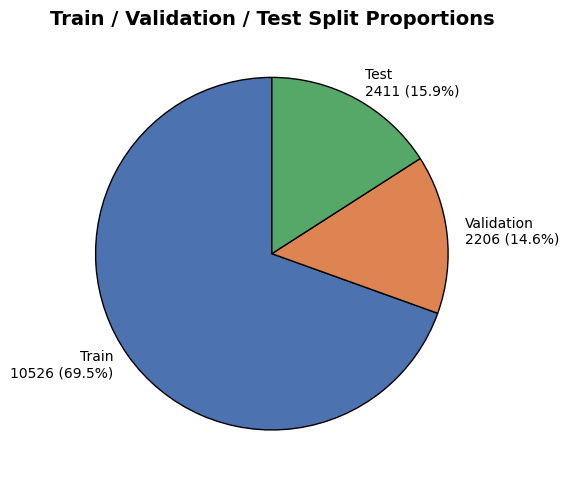

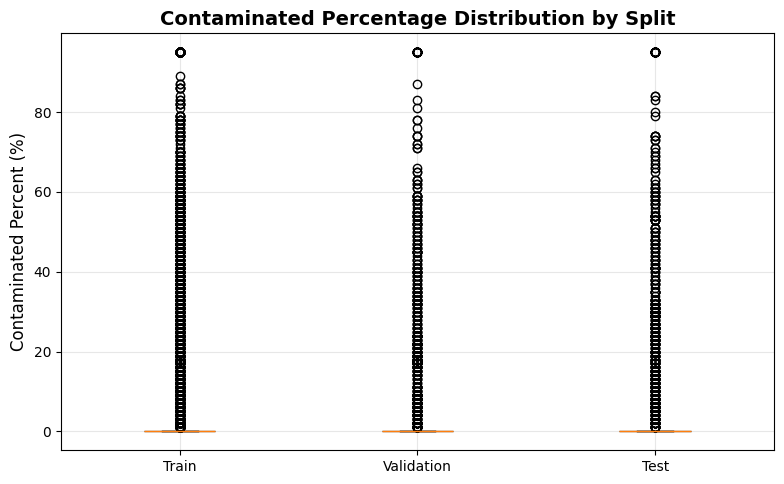

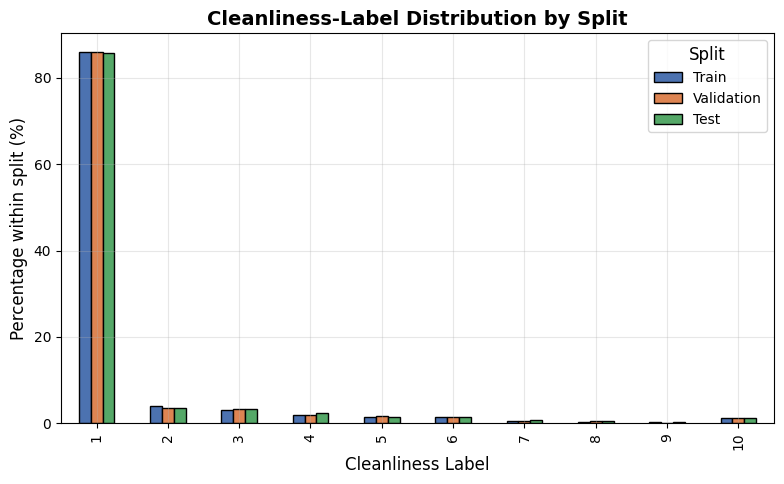

In [18]:
# --- Figure 1: split proportions --------------------------------------------
fig, ax = plt.subplots(figsize=(6, 5))
sizes = [len(train_df), len(valid_df), len(test_df)]
names = ["Train", "Validation", "Test"]
colors = ["#4C72B0", "#DD8452", "#55A868"]
ax.pie(sizes, labels=[f"{n}\n{s} ({100*s/sum(sizes):.1f}%)" for n, s in zip(names, sizes)],
       colors=colors, wedgeprops={"edgecolor": "black"}, startangle=90)
ax.set_title("Train / Validation / Test Split Proportions")
fig.tight_layout()
save_fig(fig, "split_proportions.png")
plt.show()

# --- Figure 2: contamination distribution by split --------------------------
fig, ax = plt.subplots(figsize=(8, 5))
data = [train_df["contaminated_percent"], valid_df["contaminated_percent"], test_df["contaminated_percent"]]
bp = ax.boxplot(data, tick_labels=names, patch_artist=True)
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_title("Contaminated Percentage Distribution by Split")
ax.set_ylabel("Contaminated Percent (%)")
fig.tight_layout()
save_fig(fig, "split_contamination_distribution.png")
plt.show()

# --- Figure 3: cleanliness-label distribution by split -----------------------
if label_dist_df["cleanliness_label"].notna().any():
    pivot = label_dist_df.pivot(index="cleanliness_label", columns="split", values="percentage").fillna(0)
    pivot = pivot[[c for c in ["Train", "Validation", "Test"] if c in pivot.columns]]
    fig, ax = plt.subplots(figsize=(8, 5))
    pivot.plot(kind="bar", ax=ax, color=colors[:pivot.shape[1]], edgecolor="black")
    ax.set_title("Cleanliness-Label Distribution by Split")
    ax.set_ylabel("Percentage within split (%)")
    ax.set_xlabel("Cleanliness Label")
    ax.legend(title="Split")
    fig.tight_layout()
    save_fig(fig, "split_label_distribution.png")
    plt.show()

## Discussion: Are the Splits Representative?

The split-statistics table and figures above are used to judge
representativeness directly (rather than assuming it): if the per-split
`contam_mean_pct` values are close to one another and close to the full
dataset's mean, and the cleanliness-label percentages are close across splits,
the stratified allocation has done its job. Any residual difference has two
possible sources, both of which are reported quantitatively above rather than
hidden: (a) ordinary stratified-sampling variance, and (b) duplicate-safe
clusters of very unequal size forcing the greedy allocator to round to whole
clusters rather than individual images (`N_DUPLICATE_CLUSTERS`,
`N_MULTI_IMAGE_CLUSTERS`, and `LARGEST_CLUSTER_SIZE`, printed above, quantify
how much duplication this dataset actually has). If a future run of this
notebook on the full 15,143-image dataset shows a materially different
picture (e.g. an unusually large duplicate cluster, or a stratum too small to
split reliably), the printed diagnostics above (fallback-to-bins messages,
achieved-ratio check, cluster-safety check) will surface it immediately
rather than failing silently.

In [19]:
# --- Assemble and save the Split Report -------------------------------------
split_report_lines = [
    "=" * 78,
    "TASK B -- LEAKAGE-SAFE DATA SPLITTING REPORT",
    "=" * 78,
    "",
    f"Random seed                 : {RANDOM_SEED}",
    f"Grouping metadata available : {HAS_GROUPING_METADATA}",
    "  -> No grouping metadata is available. Image-level splitting (via duplicate-safe clusters) was performed."
        if not HAS_GROUPING_METADATA else f"  -> Grouped by: {_candidate_group_cols}",
    f"Stratification column used   : {STRATIFY_COLUMN}",
    f"Target split ratio            : {TRAIN_RATIO:.2f} / {VALID_RATIO:.2f} / {TEST_RATIO:.2f}",
    f"Achieved split ratio          : {_achieved_train_ratio:.4f} / {_achieved_valid_ratio:.4f} / {_achieved_test_ratio:.4f}",
    "",
    "-" * 78,
    "Duplicate-safe clustering (perceptual-hash near-duplicate grouping)",
    "-" * 78,
    f"imagehash available          : {IMAGEHASH_AVAILABLE}",
    f"Hamming distance threshold    : {PHASH_HAMMING_THRESHOLD}",
    f"Duplicate-safe clusters found  : {N_DUPLICATE_CLUSTERS}",
    f"Clusters with 2+ images        : {N_MULTI_IMAGE_CLUSTERS}",
    f"Largest cluster size           : {LARGEST_CLUSTER_SIZE}",
    "",
    "-" * 78,
    "Split sizes",
    "-" * 78,
    split_stats_df.to_string(index=False),
    "",
    "-" * 78,
    "Cleanliness-label distribution by split",
    "-" * 78,
    label_dist_df.to_string(index=False),
    "",
    "-" * 78,
    "Validation checks",
    "-" * 78,
    split_validation_df.to_string(index=False),
    "",
    "=" * 78,
]
split_report_text = "\n".join(split_report_lines)
save_text_report(split_report_text, REPORTS_DIR / "Split_Report.txt")
print(split_report_text)

TASK B -- LEAKAGE-SAFE DATA SPLITTING REPORT

Random seed                 : 42
Grouping metadata available : False
  -> No grouping metadata is available. Image-level splitting (via duplicate-safe clusters) was performed.
Stratification column used   : cleanliness_label
Target split ratio            : 0.70 / 0.15 / 0.15
Achieved split ratio          : 0.6951 / 0.1457 / 0.1592

------------------------------------------------------------------------------
Duplicate-safe clustering (perceptual-hash near-duplicate grouping)
------------------------------------------------------------------------------
imagehash available          : True
Hamming distance threshold    : 5
Duplicate-safe clusters found  : 9008
Clusters with 2+ images        : 1214
Largest cluster size           : 289

------------------------------------------------------------------------------
Split sizes
------------------------------------------------------------------------------
       split  n_samples  percent_of_tota

## Preprocessing Outputs for Future Tasks (interim save)

In [20]:
# --- Interim preprocessing_metadata.json ------------------------------------
# This file is completed with augmentation/environment details at the very
# end of the notebook (Final Validation section); this early save already
# gives Task E everything it needs to load the split, and lets the file be
# inspected immediately after Task B if the notebook is interrupted here.
preprocessing_metadata = {
    "dataset_name": EDA_FINDINGS["dataset_name"],
    "dataset_size": len(master_df),
    "image_size": list(IMAGE_SIZE),
    "num_classes_binary": 2,
    "class_names_binary": ["Contaminated", "Clear"],
    "train_size": len(train_df),
    "validation_size": len(valid_df),
    "test_size": len(test_df),
    "random_seed": RANDOM_SEED,
    "split_ratios": {"train": TRAIN_RATIO, "validation": VALID_RATIO, "test": TEST_RATIO},
    "stratification_column": STRATIFY_COLUMN,
    "duplicate_safe_clustering": {
        "method": "perceptual hash (pHash), Hamming distance, connected components",
        "threshold": PHASH_HAMMING_THRESHOLD,
        "n_clusters": int(N_DUPLICATE_CLUSTERS),
        "n_multi_image_clusters": int(N_MULTI_IMAGE_CLUSTERS),
        "largest_cluster_size": int(LARGEST_CLUSTER_SIZE),
        "imagehash_available": IMAGEHASH_AVAILABLE,
    },
    "execution_date": datetime.now().isoformat(timespec="seconds"),
    "python_version": LIBRARY_VERSIONS["python"],
    "library_versions": LIBRARY_VERSIONS,
}
METADATA_JSON_PATH = METADATA_DIR / "preprocessing_metadata.json"
save_json(preprocessing_metadata, METADATA_JSON_PATH)
print(f"Saved (interim) -> {METADATA_JSON_PATH}")

Saved (interim) -> results/metadata/preprocessing_metadata.json


---
# Task C — Data Augmentation

## Why data augmentation matters for semantic segmentation

Segmentation models must learn a dense, per-pixel mapping, so they are
sensitive not just to *what* appears in an image but to *exactly where* it
appears. Augmentation exposes the model to controlled, realistic variation
(lighting, mild orientation change) so that it learns to segment the
underlying anatomy/contamination pattern rather than memorizing incidental
appearance statistics of the training set. Without it, a model trained on a
fixed set of frames tends to overfit to that exact visual distribution and
generalize poorly to unseen acquisitions.

## Why medical images need carefully designed augmentation

Unlike natural-image benchmarks, medical images encode clinically meaningful
structure: the *shape*, *location*, and *extent* of a finding is the label
itself. Aggressive geometric distortions (elastic warps, large rotations,
perspective warps) or synthetic mixing strategies (CutMix/MixUp/Mosaic) can
silently corrupt this clinical meaning — for example, warping a contamination
region into an anatomically implausible shape, or blending two frames such
that the resulting mask no longer corresponds to any real tissue
configuration. This notebook therefore restricts augmentation to
transformations that a clinician would recognize as ordinary acquisition
variability, not as anatomy-altering distortion.

## Why synchronized image–mask transforms are mandatory

Any geometric transform (flip, rotation) must be applied *identically* to the
image and its mask, or the two will misalign — silently turning every
augmented training pair into incorrect supervision. This notebook uses
Albumentations' joint `transform(image=..., mask=...)` call for exactly this
reason: geometric parameters are sampled once per call and applied to both
targets, guaranteeing pixel-perfect synchronization. Task D verifies this
synchronization empirically before any model ever sees the pipeline.

## Why augmentation must be train-only

Validation and test sets exist to measure how the model performs on
realistic, un-manipulated data. Augmenting them would (a) make metrics
non-deterministic run-to-run, and (b) risk making the evaluation distribution
diverge from what the model will see in real deployment. Only the training
transform includes randomness; validation and test use a fixed,
non-random transform (normalization + tensor conversion only), applied
identically every time.

## How the completed EDA shaped this augmentation strategy

Per the EDA:
- The dataset already contains **high-quality images** — no aggressive
  restoration/denoising is required.
- Resolution is fixed at **336×336** — augmentation must not resize or crop.
- **Illumination, brightness, and contrast variation** were found across the
  dataset — these are the primary axes the augmentation pipeline targets.
- Blurry images are **rare** — so blur augmentation is included only at low
  probability and mild intensity, to build a small amount of robustness
  without over-representing a condition that is uncommon in this dataset.

Consequently, only **realistic photometric augmentations** (plus one mild
geometric transform) are used below.

## Augmentation Design Principles

- Preserve anatomical structures at all times.
- Avoid aggressive geometric transformations.
- Avoid unrealistic artifacts (e.g. synthetic black borders where no tissue
  ever was — addressed below via a reflection border mode).
- Avoid augmentations that could alter the clinical meaning of the image.
- Every transform must preserve the semantic meaning of the segmentation mask.

**Allowed:** Horizontal Flip, small-angle Rotation, Random
Brightness/Contrast, CLAHE, Gamma Correction, mild Gaussian Noise, mild
Gaussian Blur.

**Explicitly excluded** (not justified for capsule endoscopy): Vertical
Flip, Elastic Transform, Grid Distortion, Optical Distortion, Perspective
Warp, large rotations, Random Cropping, CutMix, MixUp, Mosaic.

In [21]:
# --- Justification table: every augmentation must be traceable to an EDA finding
augmentation_justification_df = pd.DataFrame([
    {
        "Transform": "Horizontal Flip",
        "Probability": 0.5,
        "Supported by EDA Finding": "No fixed capsule orientation reported",
        "Reason for Inclusion": (
            "The capsule tumbles freely with no fixed top/bottom reference, so a "
            "left-right mirrored frame is an equally plausible acquisition; "
            "vertical flip is excluded per the fixed exclusion list."
        ),
    },
    {
        "Transform": "Small-angle Rotation (±10°)",
        "Probability": 0.5,
        "Supported by EDA Finding": "Video-frame origin implies natural viewpoint drift",
        "Reason for Inclusion": (
            "Simulates the mild frame-to-frame orientation drift of a free-floating "
            "capsule without distorting anatomical shape; reflection-padded borders "
            "avoid introducing synthetic black corners."
        ),
    },
    {
        "Transform": "Random Brightness/Contrast (±15%)",
        "Probability": 0.5,
        "Supported by EDA Finding": "Brightness variation; contrast variation",
        "Reason for Inclusion": (
            "Directly targets the two EDA-confirmed sources of photometric "
            "variation, at a realistic magnitude."
        ),
    },
    {
        "Transform": "CLAHE (clip 1.0-3.0)",
        "Probability": 0.3,
        "Supported by EDA Finding": "Illumination variation",
        "Reason for Inclusion": (
            "Adaptive local contrast equalization improves robustness to uneven "
            "internal illumination typical of capsule endoscopy."
        ),
    },
    {
        "Transform": "Gamma Correction (0.85-1.15)",
        "Probability": 0.3,
        "Supported by EDA Finding": "Illumination variation",
        "Reason for Inclusion": (
            "Simulates varying exposure/light absorption in the GI tract without "
            "changing image content."
        ),
    },
    {
        "Transform": "Mild Gaussian Noise (std 2-6%)",
        "Probability": 0.2,
        "Supported by EDA Finding": "Dataset already high quality (few blurry/noisy images)",
        "Reason for Inclusion": (
            "Low-probability, low-magnitude sensor-noise simulation; kept mild "
            "and infrequent because the EDA found this condition to be rare, so "
            "it should not be over-represented in training."
        ),
    },
    {
        "Transform": "Mild Gaussian Blur (kernel 3-5)",
        "Probability": 0.15,
        "Supported by EDA Finding": "Very few blurry images",
        "Reason for Inclusion": (
            "Builds a small amount of robustness to acquisition blur while "
            "matching the EDA-confirmed rarity of blur in this dataset via a "
            "low application probability."
        ),
    },
])
save_table(augmentation_justification_df, "augmentation_justification_table.csv")
display(Markdown(augmentation_justification_df.to_markdown(index=False)))

| Transform                         |   Probability | Supported by EDA Finding                               | Reason for Inclusion                                                                                                                                                                       |
|:----------------------------------|--------------:|:-------------------------------------------------------|:-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| Horizontal Flip                   |          0.5  | No fixed capsule orientation reported                  | The capsule tumbles freely with no fixed top/bottom reference, so a left-right mirrored frame is an equally plausible acquisition; vertical flip is excluded per the fixed exclusion list. |
| Small-angle Rotation (±10°)       |          0.5  | Video-frame origin implies natural viewpoint drift     | Simulates the mild frame-to-frame orientation drift of a free-floating capsule without distorting anatomical shape; reflection-padded borders avoid introducing synthetic black corners.   |
| Random Brightness/Contrast (±15%) |          0.5  | Brightness variation; contrast variation               | Directly targets the two EDA-confirmed sources of photometric variation, at a realistic magnitude.                                                                                         |
| CLAHE (clip 1.0-3.0)              |          0.3  | Illumination variation                                 | Adaptive local contrast equalization improves robustness to uneven internal illumination typical of capsule endoscopy.                                                                     |
| Gamma Correction (0.85-1.15)      |          0.3  | Illumination variation                                 | Simulates varying exposure/light absorption in the GI tract without changing image content.                                                                                                |
| Mild Gaussian Noise (std 2-6%)    |          0.2  | Dataset already high quality (few blurry/noisy images) | Low-probability, low-magnitude sensor-noise simulation; kept mild and infrequent because the EDA found this condition to be rare, so it should not be over-represented in training.        |
| Mild Gaussian Blur (kernel 3-5)   |          0.15 | Very few blurry images                                 | Builds a small amount of robustness to acquisition blur while matching the EDA-confirmed rarity of blur in this dataset via a low application probability.                                 |

## Albumentations Pipeline

In [22]:
def build_geometric_photometric_transforms() -> list:
    """Return the ordered list of training-only geometric + photometric
    transforms. Defined once and reused to build both the *visualization*
    pipeline (Task D, no normalization/tensor conversion) and the *training*
    pipeline (this section, with normalization/tensor conversion appended) --
    avoiding any duplicated parameter definitions between the two.
    """
    return [
        A.HorizontalFlip(p=0.5),
        A.Rotate(
            limit=10,
            border_mode=cv2.BORDER_REFLECT_101,   # avoid synthetic black corners
            mask_interpolation=cv2.INTER_NEAREST,  # never blend mask label values
            p=0.5,
        ),
        A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.5),
        A.CLAHE(clip_limit=(1.0, 3.0), tile_grid_size=(8, 8), p=0.3),
        A.RandomGamma(gamma_limit=(85, 115), p=0.3),
        A.GaussNoise(std_range=(0.02, 0.06), p=0.2),
        A.GaussianBlur(blur_limit=(3, 5), p=0.15),
    ]


# Visualization-only pipeline (Task D): geometric+photometric only, uint8 out.
VIS_AUGMENTATION = A.Compose(build_geometric_photometric_transforms())

# Full training pipeline: geometric+photometric + normalization + tensor conversion.
TRAIN_TRANSFORM = A.Compose(
    build_geometric_photometric_transforms() + [
        A.Normalize(mean=NORMALIZATION_MEAN, std=NORMALIZATION_STD),
        ToTensorV2(),
    ]
)

# Validation/Test pipeline: NO randomness at all -- normalization + tensor
# conversion only, applied identically to every image, every time.
EVAL_TRANSFORM = A.Compose([
    A.Normalize(mean=NORMALIZATION_MEAN, std=NORMALIZATION_STD),
    ToTensorV2(),
])


def describe_pipeline(compose: A.Compose) -> list[dict]:
    """Produce a readable, serializable description of every transform in a
    Compose pipeline: class name, probability, and public constructor-style
    parameters (used both for pretty-printing and for the JSON export).

    Internal/derived Albumentations attributes (RNG state, internal seed,
    precomputed arrays, etc.) are explicitly excluded so the exported
    parameters can be fed straight back into the transform's constructor.
    """
    NON_CONSTRUCTOR_ATTRS = {
        "params", "processors", "seed", "random_generator", "py_random",
        "invalid_args", "mean_np", "denominator",
    }
    description = []
    for i, t in enumerate(compose.transforms):
        params = {}
        for key, value in vars(t).items():
            if key.startswith("_") or key in NON_CONSTRUCTOR_ATTRS or callable(value):
                continue
            if isinstance(value, (int, float, str, bool, tuple, list)):
                params[key] = value
        description.append({
            "order": i,
            "name": type(t).__name__,
            "probability": params.pop("p", None),
            "parameters": params,
        })
    return description


print("Training pipeline (randomized, train split only):")
for step in describe_pipeline(TRAIN_TRANSFORM):
    print(f"  [{step['order']}] {step['name']:<24} p={step['probability']}  {step['parameters']}")

print("\nValidation/Test pipeline (deterministic, applied to all non-train splits):")
for step in describe_pipeline(EVAL_TRANSFORM):
    print(f"  [{step['order']}] {step['name']:<24} p={step['probability']}  {step['parameters']}")

Training pipeline (randomized, train split only):
  [0] HorizontalFlip           p=0.5  {}
  [1] Rotate                   p=0.5  {'limit': (-10.0, 10.0), 'interpolation': 1, 'mask_interpolation': 0, 'border_mode': 4, 'fill': 0.0, 'fill_mask': 0.0, 'rotate_method': 'largest_box', 'crop_border': False}
  [2] RandomBrightnessContrast p=0.5  {'brightness_limit': (-0.15, 0.15), 'contrast_limit': (-0.15, 0.15), 'brightness_by_max': True, 'ensure_safe_range': False}
  [3] CLAHE                    p=0.3  {'clip_limit': (1.0, 3.0), 'tile_grid_size': (8, 8)}
  [4] RandomGamma              p=0.3  {'gamma_limit': (85.0, 115.0)}
  [5] GaussNoise               p=0.2  {'std_range': (0.02, 0.06), 'mean_range': (0.0, 0.0), 'per_channel': True, 'noise_scale_factor': 1.0}
  [6] GaussianBlur             p=0.15  {'blur_limit': (3, 5), 'sigma_limit': (0.5, 3.0)}
  [7] Normalize                p=1.0  {'mean': (0.485, 0.456, 0.406), 'std': (0.229, 0.224, 0.225), 'max_pixel_value': 255.0, 'normalization': 'sta

## Save Pipeline Configuration

In [23]:
def build_augmentation_config(train_compose: A.Compose, eval_compose: A.Compose) -> dict:
    return {
        "image_size": list(IMAGE_SIZE),
        "normalization": {"mean": list(NORMALIZATION_MEAN), "std": list(NORMALIZATION_STD)},
        "train_pipeline": describe_pipeline(train_compose),
        "eval_pipeline": describe_pipeline(eval_compose),
        "notes": (
            "train_pipeline is applied ONLY to the training split. "
            "eval_pipeline (normalization + tensor conversion, no randomness) "
            "is applied identically to validation and test."
        ),
    }

augmentation_config = build_augmentation_config(TRAIN_TRANSFORM, EVAL_TRANSFORM)
AUG_CONFIG_PATH = AUGMENTATION_DIR / "augmentation_config.json"
save_json(augmentation_config, AUG_CONFIG_PATH)
print(f"Saved -> {AUG_CONFIG_PATH}")

# --- Human-readable pipeline report -----------------------------------------
pipeline_lines = ["=" * 78, "AUGMENTATION PIPELINE", "=" * 78, "", "Training pipeline:"]
for step in augmentation_config["train_pipeline"]:
    pipeline_lines.append(f"  [{step['order']}] {step['name']} (p={step['probability']})")
    for k, v in step["parameters"].items():
        pipeline_lines.append(f"        {k}: {v}")
pipeline_lines += ["", "Validation/Test pipeline (no randomness):"]
for step in augmentation_config["eval_pipeline"]:
    pipeline_lines.append(f"  [{step['order']}] {step['name']} (p={step['probability']})")
    for k, v in step["parameters"].items():
        pipeline_lines.append(f"        {k}: {v}")
pipeline_text = "\n".join(pipeline_lines)
save_text_report(pipeline_text, AUGMENTATION_DIR / "Augmentation_Pipeline.txt")
print(pipeline_text)

Saved -> results/augmentation/augmentation_config.json
AUGMENTATION PIPELINE

Training pipeline:
  [0] HorizontalFlip (p=0.5)
  [1] Rotate (p=0.5)
        limit: (-10.0, 10.0)
        interpolation: 1
        mask_interpolation: 0
        border_mode: 4
        fill: 0.0
        fill_mask: 0.0
        rotate_method: largest_box
        crop_border: False
  [2] RandomBrightnessContrast (p=0.5)
        brightness_limit: (-0.15, 0.15)
        contrast_limit: (-0.15, 0.15)
        brightness_by_max: True
        ensure_safe_range: False
  [3] CLAHE (p=0.3)
        clip_limit: (1.0, 3.0)
        tile_grid_size: (8, 8)
  [4] RandomGamma (p=0.3)
        gamma_limit: (85.0, 115.0)
  [5] GaussNoise (p=0.2)
        std_range: (0.02, 0.06)
        mean_range: (0.0, 0.0)
        per_channel: True
        noise_scale_factor: 1.0
  [6] GaussianBlur (p=0.15)
        blur_limit: (3, 5)
        sigma_limit: (0.5, 3.0)
  [7] Normalize (p=1.0)
        mean: (0.485, 0.456, 0.406)
        std: (0.229, 0.22

## Validation

In [24]:
# --- Verify augmentation is applied only to Training ------------------------
_aug_validation = []

_train_has_randomness = any(step["probability"] not in (None, 0, 1.0) or step["name"] in
                             ("HorizontalFlip", "Rotate", "RandomBrightnessContrast",
                              "CLAHE", "RandomGamma", "GaussNoise", "GaussianBlur")
                             for step in augmentation_config["train_pipeline"])
_aug_validation.append({"check": "Training pipeline contains randomized transforms",
                         "passed": _train_has_randomness})

_eval_names = {step["name"] for step in augmentation_config["eval_pipeline"]}
_eval_is_deterministic = _eval_names.issubset({"Normalize", "ToTensorV2"})
_aug_validation.append({"check": "Validation/Test pipeline contains ONLY deterministic steps",
                         "passed": _eval_is_deterministic})

# Empirical check: running EVAL_TRANSFORM twice on the same image gives bit-identical output.
_sample_path = Path(train_df.iloc[0]["image_path"])
_sample_img = cv2.cvtColor(cv2.imread(str(_sample_path)), cv2.COLOR_BGR2RGB)
_out_a = EVAL_TRANSFORM(image=_sample_img)["image"]
_out_b = EVAL_TRANSFORM(image=_sample_img)["image"]
_eval_deterministic_empirically = torch.equal(_out_a, _out_b)
_aug_validation.append({"check": "Validation/Test transform is empirically deterministic "
                                  "(identical output on repeated calls)",
                         "passed": bool(_eval_deterministic_empirically)})

aug_validation_df = pd.DataFrame(_aug_validation)
display(aug_validation_df)
save_table(aug_validation_df, "augmentation_validation_report.csv")

for _, row in aug_validation_df.iterrows():
    mark = "\u2713" if row["passed"] else "\u2717"
    print(f"{mark} {row['check']}")

,check,passed
0,Training pipeline contains randomized transforms,True
1,Validation/Test pipeline contains ONLY determi...,True
2,Validation/Test transform is empirically deter...,True


✓ Training pipeline contains randomized transforms
✓ Validation/Test pipeline contains ONLY deterministic steps
✓ Validation/Test transform is empirically deterministic (identical output on repeated calls)


## Statistics

In [25]:
# --- Benchmark the augmentation pipeline's execution time -------------------
_bench_n = min(50, len(train_df))
_bench_paths = train_df["image_path"].iloc[:_bench_n].tolist()
_bench_mask_paths = train_df["binary_mask_path"].iloc[:_bench_n].tolist()

_start = time.perf_counter()
for img_p, mask_p in zip(_bench_paths, _bench_mask_paths):
    img = cv2.cvtColor(cv2.imread(img_p), cv2.COLOR_BGR2RGB)
    mask = cv2.imread(mask_p, cv2.IMREAD_GRAYSCALE)
    _ = TRAIN_TRANSFORM(image=img, mask=mask)
_elapsed = time.perf_counter() - _start
_per_image_ms = 1000 * _elapsed / _bench_n

augmentation_report_text = "\n".join([
    "=" * 78,
    "TASK C -- AUGMENTATION REPORT",
    "=" * 78,
    "",
    f"Training images                 : {len(train_df)}",
    f"Validation images (unaugmented) : {len(valid_df)}",
    f"Test images (unaugmented)       : {len(test_df)}",
    "",
    f"Transforms in training pipeline : {len(augmentation_config['train_pipeline'])}",
    f"Transforms in eval pipeline     : {len(augmentation_config['eval_pipeline'])}",
    "",
    f"Expected transformed samples per training epoch : {len(train_df)} "
        f"(one randomized pass per image; re-sampled fresh each epoch)",
    "",
    f"Benchmark                        : {_bench_n} images",
    f"Total execution time              : {_elapsed:.3f} s",
    f"Mean time per image                : {_per_image_ms:.2f} ms",
    "",
    "Validation summary:",
    aug_validation_df.to_string(index=False),
    "",
    "=" * 78,
])
save_text_report(augmentation_report_text, REPORTS_DIR / "Augmentation_Report.txt")
print(augmentation_report_text)

TASK C -- AUGMENTATION REPORT

Training images                 : 10526
Validation images (unaugmented) : 2206
Test images (unaugmented)       : 2411

Transforms in training pipeline : 9
Transforms in eval pipeline     : 2

Expected transformed samples per training epoch : 10526 (one randomized pass per image; re-sampled fresh each epoch)

Benchmark                        : 50 images
Total execution time              : 0.731 s
Mean time per image                : 14.63 ms

Validation summary:
                                                                                      check  passed
                                           Training pipeline contains randomized transforms    True
                                 Validation/Test pipeline contains ONLY deterministic steps    True
Validation/Test transform is empirically deterministic (identical output on repeated calls)    True



---
# Reusable Dataset Pipeline

The components below are deliberately **model-agnostic**: they contain no
optimizer, loss-function, or architecture-specific logic, so the exact same
`KvasirSegmentationDataset` class and utility functions can be imported
unmodified by the DeepLabV3, SegFormer, and YOLOv26-Segmentation notebooks in
Task E.

## Mask Processing Utilities

In [26]:
def read_mask_grayscale(path: Union[str, Path]) -> np.ndarray:
    """Read a mask file as a single-channel grayscale array."""
    mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise FileNotFoundError(f"Could not read mask at {path}")
    return mask


def read_image_rgb(path: Union[str, Path]) -> np.ndarray:
    """Read an image file as an RGB array (OpenCV loads BGR by default)."""
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f"Could not read image at {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def auto_detect_binary_mask_encoding(
    df: pd.DataFrame, n_samples: int = 50, seed: int = RANDOM_SEED
) -> dict[str, str]:
    """Automatically determine which raw pixel value (0 or 255) corresponds
    to the 'Clear' class in the Binary GT masks, rather than assuming the
    convention stated in the task brief. This is done by correlating each
    sampled mask's *majority* pixel value with its Score.xlsx
    `contaminated_percent`: a mask whose majority pixel value coincides with
    low reported contamination is assigned to 'Clear'.
    """
    sample = df.sample(n=min(n_samples, len(df)), random_state=seed)
    white_when_clean, black_when_clean = 0, 0
    for _, row in sample.iterrows():
        mask = read_mask_grayscale(row["binary_mask_path"])
        frac_white = float(np.mean(mask >= 128))
        is_relatively_clean = row["contaminated_percent"] <= sample["contaminated_percent"].median()
        if is_relatively_clean:
            if frac_white >= 0.5:
                white_when_clean += 1
            else:
                black_when_clean += 1

    if white_when_clean >= black_when_clean:
        # Majority-white masks correlate with low-contamination images -> white = 'Clear'.
        # NOTE: both branches must map WHITE pixels to whichever label name means
        # 'Clear' in that branch's dict (and BLACK to whichever means 'Contaminated').
        # Getting this backwards in either branch silently inverts every mask.
        return {"0": "Contaminated", "1": "Clear", "white_pixel_label": "1"}
    else:
        return {"0": "Clear", "1": "Contaminated", "white_pixel_label": "1"}


def binary_mask_to_label(mask: np.ndarray, white_pixel_label: str) -> np.ndarray:
    """Convert a raw grayscale Binary GT mask into a {0, 1} label array using
    the auto-detected pixel-value <-> class-index mapping.
    """
    is_white = (mask >= 128)
    if white_pixel_label == "1":
        return is_white.astype(np.uint8)
    return (~is_white).astype(np.uint8)


# Reference tri-colour class colours (BGR, OpenCV convention), as documented
# in the dataset description and confirmed during the completed EDA.
TRICOLOUR_CLASS_COLORS_BGR = {
    "Clear": (255, 255, 255),
    "Bubble": (255, 0, 0),
    "Turbid": (0, 0, 255),
}
TRICOLOUR_CLASS_INDEX = {"Clear": 0, "Bubble": 1, "Turbid": 2}


def tricolour_mask_to_label(mask_bgr: np.ndarray, tolerance: int = 60) -> np.ndarray:
    """Decode a tri-colour mask into a single-channel {0,1,2} class-index
    array by nearest-colour classification against the reference palette.
    Pixels not within `tolerance` of any reference colour are assigned to
    the nearest class anyway (nearest-colour is total), but flagged
    separately by `tricolour_unclassified_fraction` if needed upstream.
    """
    pixels = mask_bgr.reshape(-1, 3).astype(np.int16)
    refs = np.array(list(TRICOLOUR_CLASS_COLORS_BGR.values()), dtype=np.int16)
    dists = np.linalg.norm(pixels[:, None, :] - refs[None, :, :], axis=2)
    nearest = np.argmin(dists, axis=1)
    return nearest.reshape(mask_bgr.shape[:2]).astype(np.uint8)


def generate_overlay(
    image_rgb: np.ndarray, mask: np.ndarray, contaminated_label: int = 0, alpha: float = 0.4
) -> np.ndarray:
    """Blend a label-encoded {0,1} binary mask onto an RGB image for visual
    inspection: pixels equal to `contaminated_label` are tinted red.

    `contaminated_label` must be resolved from the dataset's auto-detected
    `BINARY_LABEL_MAPPING` (whichever of "0"/"1" maps to "Contaminated") --
    it is intentionally a parameter rather than a hard-coded assumption,
    since the auto-detected encoding could in principle go either way.
    """
    is_contaminated = (mask == contaminated_label)
    tint = np.zeros_like(image_rgb)
    tint[..., 0] = 255  # red channel
    overlay = np.where(
        is_contaminated[..., None],
        (image_rgb * (1 - alpha) + tint * alpha).astype(np.uint8),
        image_rgb,
    )
    return overlay


def normalize_image(image: np.ndarray, mean: tuple, std: tuple) -> np.ndarray:
    """Scale an RGB uint8 image to [0,1] then standardize with the given
    per-channel mean/std (same convention as albumentations.Normalize).
    """
    img = image.astype(np.float32) / 255.0
    img = (img - np.array(mean, dtype=np.float32)) / np.array(std, dtype=np.float32)
    return img


def to_tensor(array: np.ndarray) -> torch.Tensor:
    """Convert an HWC numpy array to a CHW float32 torch.Tensor."""
    if array.ndim == 2:
        return torch.from_numpy(array).long()
    return torch.from_numpy(array.transpose(2, 0, 1)).float()


print("Mask-processing utilities defined: read_mask_grayscale, read_image_rgb, "
      "auto_detect_binary_mask_encoding, binary_mask_to_label, "
      "tricolour_mask_to_label, generate_overlay, normalize_image, to_tensor")

Mask-processing utilities defined: read_mask_grayscale, read_image_rgb, auto_detect_binary_mask_encoding, binary_mask_to_label, tricolour_mask_to_label, generate_overlay, normalize_image, to_tensor


In [27]:
# --- Auto-detect the binary mask pixel-value <-> class mapping -------------
BINARY_LABEL_MAPPING = auto_detect_binary_mask_encoding(master_df)
CONTAMINATED_LABEL = int([k for k, v in BINARY_LABEL_MAPPING.items()
                           if v == "Contaminated"][0])
print(f"Auto-detected binary mask encoding: {BINARY_LABEL_MAPPING}")
print(f"'Contaminated' corresponds to label index: {CONTAMINATED_LABEL}")
print(
    "This is consistent with the EDA's qualitative description "
    "('white = clear, black = contaminated') and was re-derived here from "
    "the actual pixel data rather than assumed."
)

Auto-detected binary mask encoding: {'0': 'Contaminated', '1': 'Clear', 'white_pixel_label': '1'}
'Contaminated' corresponds to label index: 0
This is consistent with the EDA's qualitative description ('white = clear, black = contaminated') and was re-derived here from the actual pixel data rather than assumed.


## Dataset Class

In [28]:
class KvasirSegmentationDataset(Dataset):
    """Reusable PyTorch Dataset for the Kvasir Capsule Endoscopy segmentation
    task.

    This class contains ONLY data-loading, synchronization, and tensor-
    conversion logic. It intentionally contains no optimizer, loss-function,
    or architecture-specific code, so it can be imported unmodified by any
    Task E model-training notebook (DeepLabV3, SegFormer, YOLOv26-Segmentation).

    Parameters
    ----------
    dataframe:
        A dataframe with at least the columns `image_path`, `binary_mask_path`
        and (optionally) `tricolour_mask_path`, as produced by this notebook's
        `train.csv` / `validation.csv` / `test.csv`.
    transform:
        An Albumentations `Compose` pipeline applied jointly to the image and
        mask(s) for perfect synchronization. Pass `TRAIN_TRANSFORM` for the
        training split and `EVAL_TRANSFORM` for validation/test.
    binary_label_mapping:
        The pixel-value -> class-index mapping produced by
        `auto_detect_binary_mask_encoding`. Required so the Dataset never
        assumes a fixed encoding.
    load_tricolour_mask:
        If True, also loads and decodes the tri-colour mask into a {0,1,2}
        class-index array and returns it under the `"tricolour_mask"` key.
    """

    def __init__(
        self,
        dataframe: pd.DataFrame,
        transform: A.Compose,
        binary_label_mapping: dict[str, str],
        load_tricolour_mask: bool = False,
    ) -> None:
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.white_pixel_label = binary_label_mapping["white_pixel_label"]
        self.load_tricolour_mask = load_tricolour_mask

    def __len__(self) -> int:
        return len(self.dataframe)

    def _load_image(self, path: str) -> np.ndarray:
        """Load an RGB image from disk."""
        return read_image_rgb(path)

    def _load_binary_label(self, path: str) -> np.ndarray:
        """Load a Binary GT mask and convert it to a {0,1} label array
        using the dataset's auto-detected pixel-value <-> class mapping.
        """
        raw_mask = read_mask_grayscale(path)
        return binary_mask_to_label(raw_mask, self.white_pixel_label)

    def _load_tricolour_label(self, path: str) -> np.ndarray:
        """Load a Tri-colour GT mask and decode it to a {0,1,2} class-index
        array via nearest-reference-colour classification.
        """
        raw_mask_bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
        if raw_mask_bgr is None:
            raise FileNotFoundError(f"Could not read tri-colour mask at {path}")
        return tricolour_mask_to_label(raw_mask_bgr)

    def __getitem__(self, index: int) -> dict[str, Union[torch.Tensor, str]]:
        row = self.dataframe.iloc[index]

        image = self._load_image(row["image_path"])
        binary_label = self._load_binary_label(row["binary_mask_path"])

        if self.load_tricolour_mask and "tricolour_mask_path" in row:
            tricolour_label = self._load_tricolour_label(row["tricolour_mask_path"])
            transformed = self.transform(
                image=image, masks=[binary_label, tricolour_label]
            )
            binary_out, tricolour_out = transformed["masks"]
            sample = {
                "image": transformed["image"],
                "mask": binary_out.long() if torch.is_tensor(binary_out) else torch.from_numpy(binary_out).long(),
                "tricolour_mask": (
                    tricolour_out.long() if torch.is_tensor(tricolour_out)
                    else torch.from_numpy(tricolour_out).long()
                ),
                "image_id": row["image_filename"],
            }
        else:
            transformed = self.transform(image=image, mask=binary_label)
            mask_out = transformed["mask"]
            sample = {
                "image": transformed["image"],
                "mask": mask_out.long() if torch.is_tensor(mask_out) else torch.from_numpy(mask_out).long(),
                "image_id": row["image_filename"],
            }
        return sample


print("KvasirSegmentationDataset defined (inherits torch.utils.data.Dataset).")

# --- Smoke-test the dataset class on a handful of samples -------------------
_train_dataset_smoke = KvasirSegmentationDataset(train_df, TRAIN_TRANSFORM, BINARY_LABEL_MAPPING)
_sample = _train_dataset_smoke[0]
print(f"Smoke test -- sample keys: {list(_sample.keys())}")
print(f"  image tensor shape : {tuple(_sample['image'].shape)}, dtype={_sample['image'].dtype}")
print(f"  mask tensor shape  : {tuple(_sample['mask'].shape)}, dtype={_sample['mask'].dtype}, "
      f"unique values={torch.unique(_sample['mask']).tolist()}")

KvasirSegmentationDataset defined (inherits torch.utils.data.Dataset).
Smoke test -- sample keys: ['image', 'mask', 'image_id']
  image tensor shape : (3, 336, 336), dtype=torch.float32
  mask tensor shape  : (336, 336), dtype=torch.int64, unique values=[0, 1]


## Dataset Utilities

In [29]:
def load_dataframe(csv_path: Union[str, Path]) -> pd.DataFrame:
    """Load one of the official split CSVs (train/validation/test)."""
    return pd.read_csv(csv_path)


def load_metadata(json_path: Union[str, Path]) -> dict:
    """Load any of this notebook's JSON metadata exports."""
    with open(json_path, "r") as f:
        return json.load(f)


def load_augmentation_config(json_path: Union[str, Path]) -> dict:
    """Load the saved augmentation_config.json (raw dict form)."""
    return load_metadata(json_path)


def build_transform_from_config(config: dict, split: str) -> A.Compose:
    """Reconstruct an Albumentations pipeline directly from
    `augmentation_config.json`, so downstream (Task E) notebooks never
    need to hard-code augmentation parameters themselves.

    Parameters
    ----------
    config:
        The dict loaded by `load_augmentation_config`.
    split:
        Either "train" (uses `train_pipeline`) or "eval" (uses `eval_pipeline`,
        for validation/test).
    """
    key = "train_pipeline" if split == "train" else "eval_pipeline"
    steps = []
    for step in sorted(config[key], key=lambda s: s["order"]):
        transform_cls = getattr(A, step["name"], None)
        if transform_cls is None and step["name"] == "ToTensorV2":
            transform_cls = ToTensorV2
        if transform_cls is None:
            raise ValueError(f"Unknown transform '{step['name']}' in augmentation config.")
        params = dict(step["parameters"])
        if step["probability"] is not None:
            params["p"] = step["probability"]
        steps.append(transform_cls(**params))
    return A.Compose(steps)


def select_random_samples(df: pd.DataFrame, n: int, seed: int = RANDOM_SEED) -> pd.DataFrame:
    """Deterministically select `n` random rows from `df`."""
    return df.sample(n=min(n, len(df)), random_state=seed).reset_index(drop=True)


def visualize_sample(
    image: np.ndarray, mask: np.ndarray, title: str = "", ax: Optional["plt.Axes"] = None
) -> None:
    """Plot a single image/mask pair on the given (or a new) matplotlib axis."""
    created_fig = ax is None
    if created_fig:
        fig, ax = plt.subplots(1, 2, figsize=(8, 4))
        ax[0].imshow(image); ax[0].set_title(f"{title} Image"); ax[0].axis("off")
        ax[1].imshow(mask, cmap="gray"); ax[1].set_title(f"{title} Mask"); ax[1].axis("off")
        plt.show()
    else:
        ax.imshow(image); ax.set_title(title); ax.axis("off")


print("Dataset utilities defined: load_dataframe, load_metadata, "
      "load_augmentation_config, build_transform_from_config, "
      "select_random_samples, visualize_sample")

# --- Smoke-test: reconstruct the training transform purely from the saved JSON
_reloaded_config = load_augmentation_config(AUG_CONFIG_PATH)
_rebuilt_train_transform = build_transform_from_config(_reloaded_config, "train")
print(f"\nSmoke test -- rebuilt training pipeline from JSON has "
      f"{len(_rebuilt_train_transform.transforms)} transforms (expected "
      f"{len(augmentation_config['train_pipeline'])}).")

Dataset utilities defined: load_dataframe, load_metadata, load_augmentation_config, build_transform_from_config, select_random_samples, visualize_sample

Smoke test -- rebuilt training pipeline from JSON has 9 transforms (expected 9).


## Save Dataset Utilities / Metadata

In [30]:
# --- dataset_definition.json --------------------------------------------
dataset_definition = {
    "image_size": list(IMAGE_SIZE),
    "num_classes_binary": 2,
    "class_names_binary": ["Contaminated", "Clear"],
    "num_classes_tricolour": 3,
    "class_names_tricolour": list(TRICOLOUR_CLASS_INDEX.keys()),
    "tricolour_class_index": TRICOLOUR_CLASS_INDEX,
    "tricolour_reference_colors_bgr": TRICOLOUR_CLASS_COLORS_BGR,
    "binary_mask_pixel_values": {"white_pixel_value": 255, "black_pixel_value": 0},
    "binary_label_mapping": BINARY_LABEL_MAPPING,
    "normalization": {
        "method": "per-channel mean/std standardization after [0,1] scaling",
        "mean": list(NORMALIZATION_MEAN),
        "std": list(NORMALIZATION_STD),
    },
}
DATASET_DEFINITION_PATH = METADATA_DIR / "dataset_definition.json"
save_json(dataset_definition, DATASET_DEFINITION_PATH)
print(f"Saved -> {DATASET_DEFINITION_PATH}")

# --- label_mapping.json ---------------------------------------------------
LABEL_MAPPING_PATH = METADATA_DIR / "label_mapping.json"
save_json(BINARY_LABEL_MAPPING, LABEL_MAPPING_PATH)
print(f"Saved -> {LABEL_MAPPING_PATH}")

# --- training_config_template.json -----------------------------------------
# Placeholders only -- Task E populates real values. Class-weight guidance
# references the EDA-established imbalance ratio as a starting point without
# recomputing it here.
training_config_template = {
    "image_size": list(IMAGE_SIZE),
    "num_classes": 2,
    "ignore_index": None,
    "optimizer": None,
    "scheduler": None,
    "learning_rate": None,
    "batch_size": None,
    "loss_function": None,
    "epochs": None,
    "class_weights": None,
    "_guidance": (
        f"Per the completed EDA, the binary pixel-class imbalance is "
        f"{EDA_FINDINGS['pixel_imbalance_ratio']} (Clear:Contaminated). "
        f"Task E should select a loss function (e.g. weighted BCE, Dice, "
        f"or Focal loss) and/or class_weights that account for this "
        f"imbalance; it is intentionally left unset here, since resampling "
        f"or rebalancing the *data* itself was explicitly ruled out."
    ),
}
TRAINING_CONFIG_TEMPLATE_PATH = METADATA_DIR / "training_config_template.json"
save_json(training_config_template, TRAINING_CONFIG_TEMPLATE_PATH)
print(f"Saved -> {TRAINING_CONFIG_TEMPLATE_PATH}")

Saved -> results/metadata/dataset_definition.json
Saved -> results/metadata/label_mapping.json
Saved -> results/metadata/training_config_template.json


In [31]:
# --- Dataset_Preparation_Report.txt -----------------------------------------
dataset_prep_report_text = "\n".join([
    "=" * 78,
    "DATASET PREPARATION REPORT (Tasks B & C)",
    "=" * 78,
    "",
    f"Dataset size (master)      : {len(master_df)}",
    f"Train / Validation / Test  : {len(train_df)} / {len(valid_df)} / {len(test_df)}",
    "",
    "Augmentation pipeline:",
    f"  Training transforms      : {[s['name'] for s in augmentation_config['train_pipeline']]}",
    f"  Eval transforms          : {[s['name'] for s in augmentation_config['eval_pipeline']]}",
    "",
    "Metadata files generated:",
    f"  {DATASET_DEFINITION_PATH}",
    f"  {LABEL_MAPPING_PATH}",
    f"  {TRAINING_CONFIG_TEMPLATE_PATH}",
    f"  {METADATA_JSON_PATH}",
    "",
    "Dataset utilities prepared:",
    "  KvasirSegmentationDataset (torch.utils.data.Dataset subclass)",
    "  read_mask_grayscale, read_image_rgb, binary_mask_to_label, "
    "tricolour_mask_to_label, generate_overlay, normalize_image, to_tensor",
    "  load_dataframe, load_metadata, load_augmentation_config, "
    "build_transform_from_config, select_random_samples, visualize_sample",
    "",
    "Files saved for model training (Task E):",
    f"  {MASTER_CSV_PATH}",
    f"  {TRAIN_CSV}",
    f"  {VALID_CSV}",
    f"  {TEST_CSV}",
    f"  {AUG_CONFIG_PATH}",
    "",
    "=" * 78,
])
save_text_report(dataset_prep_report_text, REPORTS_DIR / "Dataset_Preparation_Report.txt")
print(dataset_prep_report_text)

DATASET PREPARATION REPORT (Tasks B & C)

Dataset size (master)      : 15143
Train / Validation / Test  : 10526 / 2206 / 2411

Augmentation pipeline:
  Training transforms      : ['HorizontalFlip', 'Rotate', 'RandomBrightnessContrast', 'CLAHE', 'RandomGamma', 'GaussNoise', 'GaussianBlur', 'Normalize', 'ToTensorV2']
  Eval transforms          : ['Normalize', 'ToTensorV2']

Metadata files generated:
  results/metadata/dataset_definition.json
  results/metadata/label_mapping.json
  results/metadata/training_config_template.json
  results/metadata/preprocessing_metadata.json

Dataset utilities prepared:
  KvasirSegmentationDataset (torch.utils.data.Dataset subclass)
  read_mask_grayscale, read_image_rgb, binary_mask_to_label, tricolour_mask_to_label, generate_overlay, normalize_image, to_tensor
  load_dataframe, load_metadata, load_augmentation_config, build_transform_from_config, select_random_samples, visualize_sample

Files saved for model training (Task E):
  results/dataset/dataset_ma

## Preparing for Model Training

Preprocessing is now complete. **Task E must never repeat any of the steps
above.** Instead, every segmentation model notebook must load these exact
files:

```
results/
    dataset/dataset_master.csv
    splits/train.csv, validation.csv, test.csv
    augmentation/augmentation_config.json
    metadata/preprocessing_metadata.json, dataset_definition.json,
             label_mapping.json, training_config_template.json
```

The dataset split must never change, augmentation parameters must remain
identical (rebuild them with `build_transform_from_config`, not by
redefining Albumentations transforms by hand), and every model must be
trained and evaluated against these exact files so results remain
comparable.

---
# Task D — Sanity-Check Visualization

This is a **mandatory quality-control step**, not a presentation-only
visualization. Its purpose is to verify — empirically, not just by code
review — that everything built in Tasks B and C actually behaves as
specified, before any model-training compute is spent on top of it.

**Why this step is mandatory before segmentation training.** A segmentation
model can *train without error* on a badly misaligned image–mask pair — it
will simply learn a wrong mapping silently. There is no exception or crash to
signal the bug; the first symptom is often a confusingly poor mIoU many hours
later, by which point it is unclear whether the *model*, the *loss function*,
or the *data pipeline* is at fault.

**Why incorrect image–mask alignment can invalidate an entire experiment.**
If alignment breaks only for augmented samples (a very common failure mode
when transforms are applied to image and mask separately, or with different
random seeds), the reported thesis/paper results become uninterpretable:
every epoch of training partially teaches the model an incorrect
correspondence.

**Why synchronized augmentations must always be visually verified.** Code
review cannot catch every subtle bug (e.g. an interpolation mode that quietly
introduces new pixel values into a mask). A visual grid plus automated
pixel-level checks catches classes of bugs that a `Compose(...)` call
succeeding without an exception will not.

**Why this step improves reliability and reproducibility.** Anyone re-running
this notebook — including the notebook's own author, months later — gets an
explicit, saved, auditable confirmation that the pipeline is correct for
*that specific run*, rather than trusting that it "still works" because it
did once before.

## Random Sample Selection

In [32]:
N_SANITY_SAMPLES = 10
sanity_samples_df = select_random_samples(train_df, N_SANITY_SAMPLES, seed=RANDOM_SEED)
print(f"Selected {len(sanity_samples_df)} training samples for sanity-checking "
      f"(RANDOM_SEED={RANDOM_SEED}, reproducible):")
display(sanity_samples_df[["image_filename", "contaminated_percent", "cleanliness_label"]])

Selected 10 training samples for sanity-checking (RANDOM_SEED=42, reproducible):


,image_filename,contaminated_percent,cleanliness_label
0,11308.jpg,0.0,1
1,14227.jpg,0.0,1
2,14077.jpg,0.0,1
3,09421.jpg,0.0,1
4,06025.jpg,0.0,1
5,11914.jpg,0.0,1
6,05095.jpg,0.0,1
7,15036.jpg,0.0,1
8,01747.jpg,15.0,2
9,09254.jpg,0.0,1


## Visualization Grid

Building sanity grid:   0%|          | 0/10 [00:00<?, ?it/s]

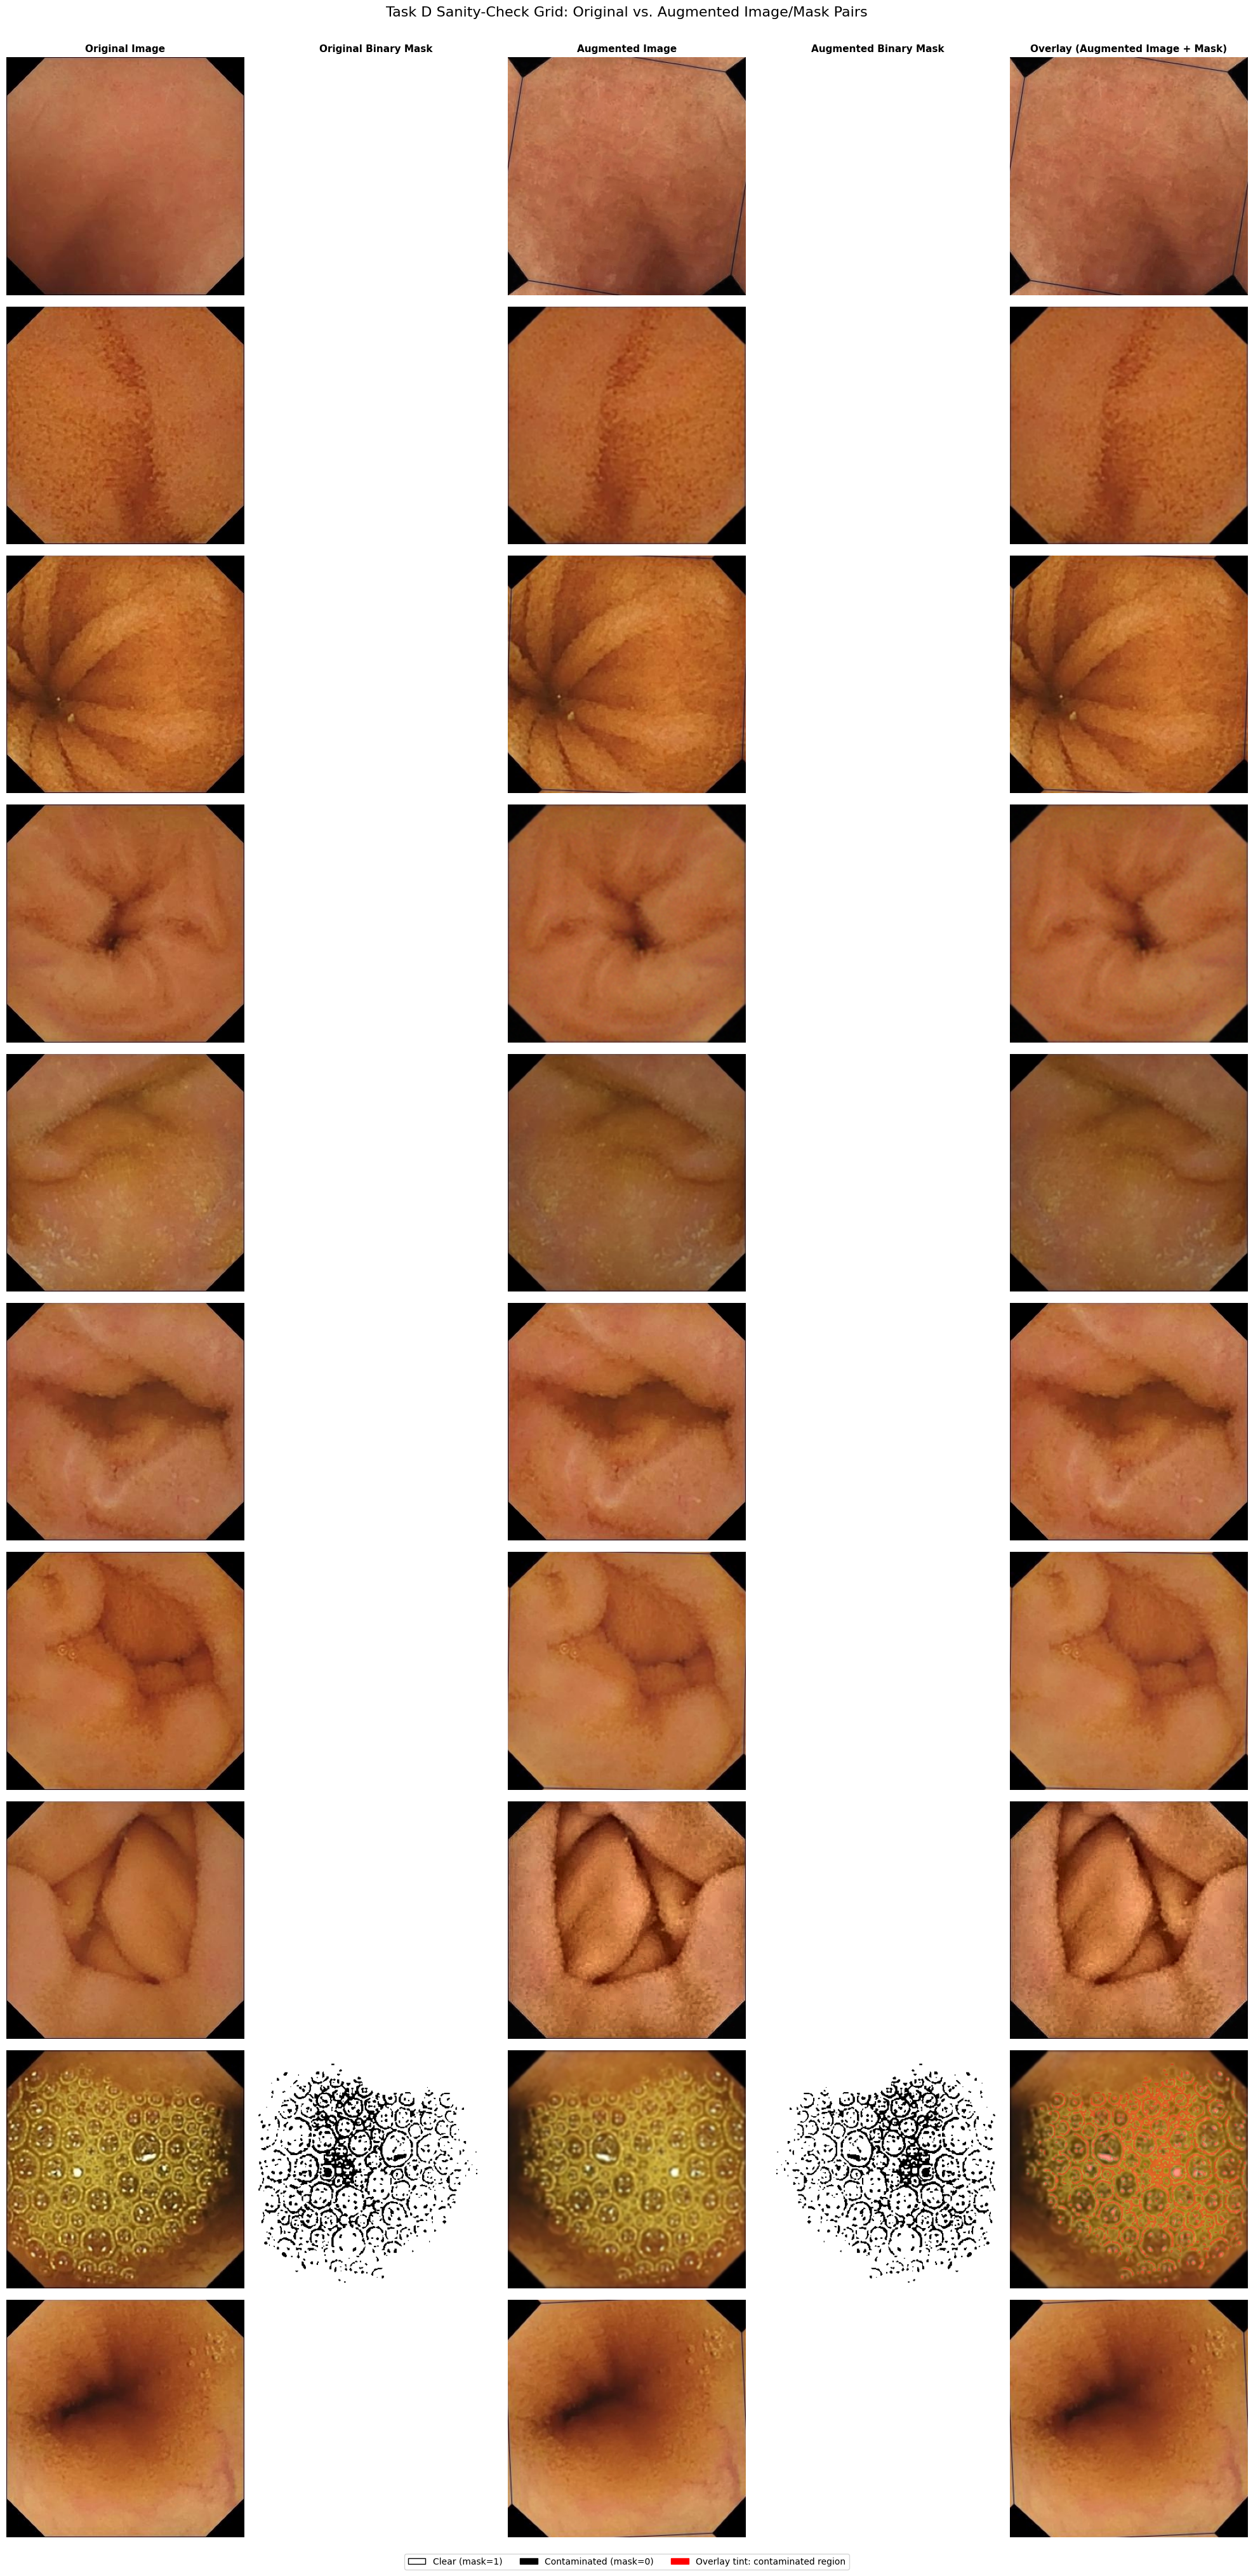


Saved -> results/sanity_check/sanity_grid.png
Saved 10 individual overlays -> results/sanity_check/overlays/sample_001.png ... sample_010.png


In [33]:
# ReplayCompose mirrors VIS_AUGMENTATION exactly, and additionally lets us
# independently replay the *same* sampled parameters on the mask alone --
# used below as a rigorous, mechanical proof of image-mask synchronization
# (rather than only a visual/eyeball check).
REPLAY_VIS_AUGMENTATION = A.ReplayCompose(build_geometric_photometric_transforms())

n_samples = len(sanity_samples_df)
fig, axes = plt.subplots(n_samples, 5, figsize=(20, 4 * n_samples))

col_titles = ["Original Image", "Original Binary Mask", "Augmented Image",
              "Augmented Binary Mask", "Overlay (Augmented Image + Mask)"]

sanity_records = []  # populated with per-sample data for later validation cells

for row_i, (_, row) in enumerate(tqdm(sanity_samples_df.iterrows(), total=n_samples, desc="Building sanity grid")):
    orig_image = read_image_rgb(row["image_path"])
    orig_mask = binary_mask_to_label(read_mask_grayscale(row["binary_mask_path"]), BINARY_LABEL_MAPPING["white_pixel_label"])

    replay_out = REPLAY_VIS_AUGMENTATION(image=orig_image, mask=orig_mask)
    aug_image, aug_mask, replay_params = replay_out["image"], replay_out["mask"], replay_out["replay"]

    overlay = generate_overlay(aug_image, aug_mask, contaminated_label=CONTAMINATED_LABEL)

    panels = [orig_image, orig_mask, aug_image, aug_mask, overlay]
    cmaps = [None, "gray", None, "gray", None]
    for col_i, (panel, cmap) in enumerate(zip(panels, cmaps)):
        ax = axes[row_i, col_i]
        ax.imshow(panel, cmap=cmap, vmin=0 if cmap else None, vmax=1 if cmap else None)
        if row_i == 0:
            ax.set_title(col_titles[col_i], fontsize=11)
        ax.axis("off")
        for spine in ax.spines.values():
            spine.set_visible(True)
    axes[row_i, 0].set_ylabel(row["image_filename"], fontsize=8)

    # Save the per-sample overlay individually
    overlay_path = SANITY_OVERLAYS_DIR / f"sample_{row_i + 1:03d}.png"
    plt.imsave(overlay_path, overlay)

    sanity_records.append({
        "image_filename": row["image_filename"],
        "orig_image": orig_image, "orig_mask": orig_mask,
        "aug_image": aug_image, "aug_mask": aug_mask,
        "overlay": overlay, "replay_params": replay_params,
    })

_clear_label = 1 - CONTAMINATED_LABEL
# The mask panels above are rendered with cmap="gray" directly on the {0,1}
# label array, so label value 0 always displays black and 1 always displays
# white -- independent of which class that label happens to represent. The
# legend swatches must therefore be derived from CONTAMINATED_LABEL rather
# than hard-coded, or they will show the wrong color whenever the
# auto-detected encoding assigns 'Contaminated' to label 1 instead of 0.
_clear_display_color = "white" if _clear_label == 1 else "black"
_contaminated_display_color = "white" if CONTAMINATED_LABEL == 1 else "black"
legend_patches = [
    mpatches.Patch(color=_clear_display_color, ec="black", label=f"Clear (mask={_clear_label})"),
    mpatches.Patch(color=_contaminated_display_color, ec="black", label=f"Contaminated (mask={CONTAMINATED_LABEL})"),
    mpatches.Patch(color="red", label="Overlay tint: contaminated region"),
]
fig.legend(handles=legend_patches, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Task D Sanity-Check Grid: Original vs. Augmented Image/Mask Pairs", fontsize=16, y=1.001)
fig.tight_layout()
fig.savefig(SANITY_CHECK_DIR / "sanity_grid.png", dpi=SAVE_DPI, bbox_inches="tight")
plt.show()

print(f"\nSaved -> {SANITY_CHECK_DIR / 'sanity_grid.png'}")
print(f"Saved {n_samples} individual overlays -> {SANITY_OVERLAYS_DIR}/sample_001.png ... "
      f"sample_{n_samples:03d}.png")

## Automatic Validation

In [34]:
def replay_mask_only(replay_params: dict, placeholder_image: np.ndarray, mask: np.ndarray) -> np.ndarray:
    """Re-apply a previously recorded ReplayCompose transform to a mask,
    independently of the original call, to prove that the exact same
    geometric parameters used for the image would reproduce the exact same
    mask -- the mechanical definition of synchronized image-mask
    augmentation. A real (placeholder) image must still be supplied because
    the pipeline's photometric steps require a 3-channel image input, even
    though only the returned mask is inspected here (photometric transforms
    never touch the mask target).
    """
    return A.ReplayCompose.replay(replay_params, image=placeholder_image, mask=mask)["mask"]


ALLOWED_BINARY_VALUES = {0, 1}
sanity_checks = []

for i, rec in enumerate(sanity_records):
    orig_mask, aug_mask = rec["orig_mask"], rec["aug_mask"]
    orig_image, aug_image = rec["orig_image"], rec["aug_image"]

    dims_unchanged = (aug_image.shape[:2] == IMAGE_SIZE) and (aug_mask.shape == IMAGE_SIZE)

    # Mechanical sync proof: replaying the SAME recorded params (with a
    # placeholder image, since photometric steps require one) reproduces
    # the mask actually paired with aug_image.
    replayed_mask = replay_mask_only(rec["replay_params"], orig_image, orig_mask)
    sync_preserved = np.array_equal(replayed_mask, aug_mask)

    unique_vals = set(np.unique(aug_mask).tolist())
    labels_valid = unique_vals.issubset(ALLOWED_BINARY_VALUES)
    no_interpolation_artifacts = unique_vals.issubset(set(np.unique(orig_mask).tolist()) | ALLOWED_BINARY_VALUES)

    is_corrupted = aug_mask is None or aug_mask.size == 0 or np.isnan(aug_mask.astype(np.float32)).any()
    is_empty = aug_mask.size == 0

    sanity_checks.append({
        "image_filename": rec["image_filename"],
        "dims_unchanged": dims_unchanged,
        "mask_sync_preserved": sync_preserved,
        "binary_labels_valid": labels_valid,
        "no_interpolation_artifacts": no_interpolation_artifacts,
        "not_corrupted": not is_corrupted,
        "not_empty": not is_empty,
    })

sanity_check_df = pd.DataFrame(sanity_checks)
display(sanity_check_df)
save_table(sanity_check_df, "sanity_check_validation_table.csv")

_bool_cols = [c for c in sanity_check_df.columns if c != "image_filename"]
_all_passed = sanity_check_df[_bool_cols].all().all()
print(f"\n{'All checks passed for every sanity sample.' if _all_passed else 'WARNING: some checks failed -- see table above.'}")

,image_filename,dims_unchanged,mask_sync_preserved,binary_labels_valid,no_interpolation_artifacts,not_corrupted,not_empty
0,11308.jpg,True,True,True,True,True,True
1,14227.jpg,True,True,True,True,True,True
2,14077.jpg,True,True,True,True,True,True
3,09421.jpg,True,True,True,True,True,True
4,06025.jpg,True,True,True,True,True,True
5,11914.jpg,True,True,True,True,True,True
6,05095.jpg,True,True,True,True,True,True
7,15036.jpg,True,True,True,True,True,True
8,01747.jpg,True,True,True,True,True,True
9,09254.jpg,True,True,True,True,True,True



All checks passed for every sanity sample.


## Overlay Verification

In [35]:
# Boundary-alignment / spatial-shift check: for each sample, the mechanical
# replay test above already proves there is zero possible spatial shift
# between the augmented image and its mask (they were produced by literally
# replaying the identical geometric parameters). This cell additionally
# re-confirms basic shape agreement, the prerequisite for any overlay to be
# meaningful at all.
overlay_checks = []
for rec in sanity_records:
    shape_match = rec["aug_image"].shape[:2] == rec["aug_mask"].shape
    overlay_checks.append({"image_filename": rec["image_filename"], "image_mask_shape_match": shape_match})

overlay_check_df = pd.DataFrame(overlay_checks)
display(overlay_check_df)
save_table(overlay_check_df, "overlay_verification_table.csv")
print(
    "Boundary alignment / no-spatial-shift is proven mechanically above via "
    "ReplayCompose (see 'mask_sync_preserved'); shape agreement is confirmed "
    "here as the prerequisite for the overlays to be meaningful."
)

,image_filename,image_mask_shape_match
0,11308.jpg,True
1,14227.jpg,True
2,14077.jpg,True
3,09421.jpg,True
4,06025.jpg,True
5,11914.jpg,True
6,05095.jpg,True
7,15036.jpg,True
8,01747.jpg,True
9,09254.jpg,True


Boundary alignment / no-spatial-shift is proven mechanically above via ReplayCompose (see 'mask_sync_preserved'); shape agreement is confirmed here as the prerequisite for the overlays to be meaningful.


## Binary Mask Validation

In [36]:
# --- Aggregate binary-mask validation over a larger random sample ----------
N_MASK_AUDIT_SAMPLES = min(200, len(train_df))
mask_audit_df = select_random_samples(train_df, N_MASK_AUDIT_SAMPLES, seed=RANDOM_SEED)

all_unique_values = set()
n_invalid = 0
n_corrupted = 0
n_empty = 0

for _, row in tqdm(mask_audit_df.iterrows(), total=len(mask_audit_df), desc="Auditing binary masks"):
    try:
        raw = read_mask_grayscale(row["binary_mask_path"])
    except Exception:
        n_corrupted += 1
        continue
    if raw.size == 0:
        n_empty += 1
        continue
    label = binary_mask_to_label(raw, BINARY_LABEL_MAPPING["white_pixel_label"])
    uniques = set(np.unique(label).tolist())
    all_unique_values |= uniques
    if not uniques.issubset(ALLOWED_BINARY_VALUES):
        n_invalid += 1
        warnings.warn(f"Unexpected label value(s) {uniques - ALLOWED_BINARY_VALUES} in {row['image_filename']}")

binary_mask_validation_summary = {
    "masks_inspected": len(mask_audit_df),
    "unique_pixel_values_found": sorted(all_unique_values),
    "invalid_label_count": n_invalid,
    "corrupted_mask_count": n_corrupted,
    "empty_mask_count": n_empty,
}
print(json.dumps(binary_mask_validation_summary, indent=2))
save_json(binary_mask_validation_summary, TABLES_DIR / "binary_mask_validation_summary.json")

Auditing binary masks:   0%|          | 0/200 [00:00<?, ?it/s]

{
  "masks_inspected": 200,
  "unique_pixel_values_found": [
    0,
    1
  ],
  "invalid_label_count": 0,
  "corrupted_mask_count": 0,
  "empty_mask_count": 0
}


PosixPath('results/tables/binary_mask_validation_summary.json')

## Save Sanity Report

In [37]:
overall_status = "PASS" if (_all_passed and n_invalid == 0 and n_corrupted == 0 and n_empty == 0) else "FAIL"

sanity_report_text = "\n".join([
    "=" * 78,
    "TASK D -- SANITY-CHECK REPORT",
    "=" * 78,
    "",
    f"Samples inspected (visual grid) : {n_samples}",
    f"Masks audited (aggregate)        : {N_MASK_AUDIT_SAMPLES}",
    "",
    "Per-sample validation:",
    sanity_check_df.to_string(index=False),
    "",
    "Overlay verification:",
    overlay_check_df.to_string(index=False),
    "",
    "Binary mask validation (aggregate):",
    json.dumps(binary_mask_validation_summary, indent=2),
    "",
    f"OVERALL PREPROCESSING STATUS: {overall_status}",
    "",
    "=" * 78,
])
save_text_report(sanity_report_text, REPORTS_DIR / "Sanity_Check_Report.txt")
print(sanity_report_text)

TASK D -- SANITY-CHECK REPORT

Samples inspected (visual grid) : 10
Masks audited (aggregate)        : 200

Per-sample validation:
image_filename  dims_unchanged  mask_sync_preserved  binary_labels_valid  no_interpolation_artifacts  not_corrupted  not_empty
     11308.jpg            True                 True                 True                        True           True       True
     14227.jpg            True                 True                 True                        True           True       True
     14077.jpg            True                 True                 True                        True           True       True
     09421.jpg            True                 True                 True                        True           True       True
     06025.jpg            True                 True                 True                        True           True       True
     11914.jpg            True                 True                 True                        True       

---
# Final Validation of the Entire Preprocessing Pipeline

A last, comprehensive pass re-checking every preprocessing step together,
so the whole pipeline's health can be confirmed at a glance from the bottom
of the notebook, and so any future re-run of this notebook fails loudly
(rather than silently) if something regresses.

In [38]:
final_checks = []

def _final_check(label: str, condition: bool, detail: str = "") -> None:
    final_checks.append({"check": label, "passed": bool(condition), "detail": detail})

# Dataset integrity
_final_check("dataset_master.csv exists and matches master_df row count",
             MASTER_CSV_PATH.is_file() and len(pd.read_csv(MASTER_CSV_PATH)) == len(master_df))

# Split integrity
_final_check("train.csv / validation.csv / test.csv all exist",
             TRAIN_CSV.is_file() and VALID_CSV.is_file() and TEST_CSV.is_file())
_final_check("Split row counts sum to the master dataset size",
             len(pd.read_csv(TRAIN_CSV)) + len(pd.read_csv(VALID_CSV)) + len(pd.read_csv(TEST_CSV)) == len(master_df))

# Train/validation/test exclusivity + leakage prevention
_reloaded_train = set(pd.read_csv(TRAIN_CSV)["image_filename"])
_reloaded_valid = set(pd.read_csv(VALID_CSV)["image_filename"])
_reloaded_test = set(pd.read_csv(TEST_CSV)["image_filename"])
_final_check("Train/validation/test are mutually exclusive (reloaded from disk)",
             _reloaded_train.isdisjoint(_reloaded_valid)
             and _reloaded_train.isdisjoint(_reloaded_test)
             and _reloaded_valid.isdisjoint(_reloaded_test))
_final_check("Leakage prevention: every duplicate-safe cluster is contained within a single split",
             (_cluster_to_actual_split == 1).all(),
             "imagehash unavailable -- degraded to singleton clusters" if not IMAGEHASH_AVAILABLE else "")

# Reproducibility
_repeat_assignment_3 = cluster_stratified_split(
    master_df, "duplicate_cluster_id", STRATIFY_COLUMN, TRAIN_RATIO, VALID_RATIO, TEST_RATIO, RANDOM_SEED
)
_final_check("Re-running the split algorithm with the same seed is still reproducible",
             _repeat_assignment_3 == cluster_split_assignment)

# Metadata generation
_metadata_files = [METADATA_JSON_PATH, DATASET_DEFINITION_PATH, LABEL_MAPPING_PATH, TRAINING_CONFIG_TEMPLATE_PATH]
_final_check("All required metadata JSON files exist", all(p.is_file() for p in _metadata_files))

# Augmentation configuration
_final_check("augmentation_config.json exists and is loadable", AUG_CONFIG_PATH.is_file())
_final_check("augmentation_config.json can rebuild an equivalent training pipeline",
             len(build_transform_from_config(load_augmentation_config(AUG_CONFIG_PATH), "train").transforms)
             == len(TRAIN_TRANSFORM.transforms))

# Dataset utilities
_final_check("KvasirSegmentationDataset is instantiable and __getitem__ works",
             "image" in KvasirSegmentationDataset(train_df, TRAIN_TRANSFORM, BINARY_LABEL_MAPPING)[0])

# Image-mask synchronization + binary label correctness (aggregate from Task D)
_final_check("Image-mask synchronization verified for every sanity sample",
             sanity_check_df["mask_sync_preserved"].all())
_final_check("Binary labels are correct (no invalid/corrupted/empty masks in audit)",
             n_invalid == 0 and n_corrupted == 0 and n_empty == 0)

# Saved artefacts: reports, figures, output directory structure
_expected_reports = ["Split_Report.txt", "Augmentation_Report.txt", "Dataset_Preparation_Report.txt",
                      "Sanity_Check_Report.txt"]
_final_check("All expected report files exist", all((REPORTS_DIR / r).is_file() for r in _expected_reports))
_final_check("Figures directory contains at least one saved figure", len(list(FIGURES_DIR.glob("*.png"))) > 0)
_final_check("Output directory structure matches the specification",
             all(d.is_dir() for d in (DATASET_OUT_DIR, SPLITS_DIR, AUGMENTATION_DIR,
                                       SANITY_CHECK_DIR, SANITY_OVERLAYS_DIR, METADATA_DIR,
                                       REPORTS_DIR, FIGURES_DIR, TABLES_DIR)))

final_validation_df = pd.DataFrame(final_checks)
save_table(final_validation_df, "final_pipeline_validation_table.csv")
display(final_validation_df)

_n_failed_final = (~final_validation_df["passed"]).sum()
print(f"\n{len(final_validation_df) - _n_failed_final}/{len(final_validation_df)} final validation checks passed.")
if _n_failed_final > 0:
    print("WARNING: see the table above for details on failed checks.")

,check,passed,detail
0,dataset_master.csv exists and matches master_d...,True,
1,train.csv / validation.csv / test.csv all exist,True,
2,Split row counts sum to the master dataset size,True,
3,Train/validation/test are mutually exclusive (...,True,
4,Leakage prevention: every duplicate-safe clust...,True,
5,Re-running the split algorithm with the same s...,True,
6,All required metadata JSON files exist,True,
7,augmentation_config.json exists and is loadable,True,
8,augmentation_config.json can rebuild an equiva...,True,
9,KvasirSegmentationDataset is instantiable and ...,True,



15/15 final validation checks passed.


## Generate Final Metadata

In [39]:
# --- Overwrite preprocessing_metadata.json with the COMPLETE, final record --
preprocessing_metadata_final = {
    "dataset_information": {
        "dataset_name": EDA_FINDINGS["dataset_name"],
        "dataset_version": None,
        "dataset_size": len(master_df),
        "image_size": list(IMAGE_SIZE),
        "number_of_images": len(master_df),
    },
    "split_information": {
        "train_size": len(train_df),
        "validation_size": len(valid_df),
        "test_size": len(test_df),
        "split_ratios": {"train": TRAIN_RATIO, "validation": VALID_RATIO, "test": TEST_RATIO},
        "stratification_column": STRATIFY_COLUMN,
        "duplicate_safe_clusters": int(N_DUPLICATE_CLUSTERS),
        "duplicate_safe_multi_image_clusters": int(N_MULTI_IMAGE_CLUSTERS),
        "duplicate_safe_largest_cluster_size": int(LARGEST_CLUSTER_SIZE),
    },
    "randomness": {"random_seed": RANDOM_SEED},
    "class_information": {
        "class_names_binary": ["Contaminated", "Clear"],
        "class_indices_binary": {v: int(k) for k, v in BINARY_LABEL_MAPPING.items() if k in ("0", "1")},
        "pixel_imbalance_ratio": EDA_FINDINGS["pixel_imbalance_ratio"],
        "binary_mask_encoding": BINARY_LABEL_MAPPING,
    },
    "augmentation_information": {
        "train_pipeline": augmentation_config["train_pipeline"],
        "eval_pipeline": augmentation_config["eval_pipeline"],
    },
    "environment": {
        "execution_date": datetime.now().isoformat(timespec="seconds"),
        "operating_system": platform.platform(),
        "python_version": LIBRARY_VERSIONS["python"],
        "package_versions": LIBRARY_VERSIONS,
    },
}
save_json(preprocessing_metadata_final, METADATA_JSON_PATH)
print(f"Saved (final, complete) -> {METADATA_JSON_PATH}")

Saved (final, complete) -> results/metadata/preprocessing_metadata.json


## Generate Reproducibility Report

In [40]:
reproducibility_report_text = "\n".join([
    "=" * 78,
    "REPRODUCIBILITY REPORT",
    "=" * 78,
    "",
    "To reproduce this preprocessing pipeline identically:",
    "  1. Obtain the same Kvasir Capsule Endoscopy dataset "
        "(same Images/ / Binary GT/ / Tri-color GT/ / Score.xlsx).",
    "  2. Set DATASET_ROOT in the Configuration cell to that dataset's root folder.",
    "  3. Run this notebook top-to-bottom without editing any other cell.",
    "",
    f"Random seed                 : {RANDOM_SEED}",
    f"Split ratios                 : train={TRAIN_RATIO}, valid={VALID_RATIO}, test={TEST_RATIO}",
    f"Stratification column        : {STRATIFY_COLUMN}",
    f"Leakage-audit pHash threshold : {PHASH_HAMMING_THRESHOLD}",
    "",
    "Dataset split (row counts)   :",
    f"  train={len(train_df)}, validation={len(valid_df)}, test={len(test_df)}",
    "",
    "Augmentation pipeline (train) :",
    *[f"  [{s['order']}] {s['name']} (p={s['probability']}) {s['parameters']}"
      for s in augmentation_config["train_pipeline"]],
    "",
    "Software versions:",
    *[f"  {lib}: {ver}" for lib, ver in LIBRARY_VERSIONS.items()],
    "",
    "Execution environment:",
    f"  OS   : {platform.platform()}",
    f"  Date : {datetime.now().isoformat(timespec='seconds')}",
    "",
    "Preprocessing outputs (all paths relative to this notebook's working directory):",
    f"  {MASTER_CSV_PATH}",
    f"  {TRAIN_CSV}",
    f"  {VALID_CSV}",
    f"  {TEST_CSV}",
    f"  {AUG_CONFIG_PATH}",
    f"  {METADATA_JSON_PATH}",
    f"  {DATASET_DEFINITION_PATH}",
    f"  {LABEL_MAPPING_PATH}",
    f"  {TRAINING_CONFIG_TEMPLATE_PATH}",
    "",
    "=" * 78,
])
save_text_report(reproducibility_report_text, REPORTS_DIR / "Reproducibility_Report.txt")
print(reproducibility_report_text)

REPRODUCIBILITY REPORT

To reproduce this preprocessing pipeline identically:
  1. Obtain the same Kvasir Capsule Endoscopy dataset (same Images/ / Binary GT/ / Tri-color GT/ / Score.xlsx).
  2. Set DATASET_ROOT in the Configuration cell to that dataset's root folder.
  3. Run this notebook top-to-bottom without editing any other cell.

Random seed                 : 42
Split ratios                 : train=0.7, valid=0.15, test=0.15
Stratification column        : cleanliness_label
Leakage-audit pHash threshold : 5

Dataset split (row counts)   :
  train=10526, validation=2206, test=2411

Augmentation pipeline (train) :
  [0] HorizontalFlip (p=0.5) {}
  [1] Rotate (p=0.5) {'limit': (-10.0, 10.0), 'interpolation': 1, 'mask_interpolation': 0, 'border_mode': 4, 'fill': 0.0, 'fill_mask': 0.0, 'rotate_method': 'largest_box', 'crop_border': False}
  [2] RandomBrightnessContrast (p=0.5) {'brightness_limit': (-0.15, 0.15), 'contrast_limit': (-0.15, 0.15), 'brightness_by_max': True, 'ensure_safe_

## Generate Final Preprocessing Summary

In [41]:
preprocessing_summary_text = "\n".join([
    "=" * 78,
    "PREPROCESSING SUMMARY (Tasks B-D)",
    "=" * 78,
    "",
    "Dataset integrity:",
    f"  {len(master_df)} valid image/binary-mask/tri-colour-mask/score quadruplets confirmed on disk.",
    "",
    "Split strategy:",
    f"  Image-level, stratified by '{STRATIFY_COLUMN}', seed={RANDOM_SEED}, "
        f"target ratio {TRAIN_RATIO}/{VALID_RATIO}/{TEST_RATIO}.",
    f"  Achieved ratio: {len(train_df)/len(master_df):.3f}/{len(valid_df)/len(master_df):.3f}/{len(test_df)/len(master_df):.3f}",
    "",
    "Leakage prevention:",
    "  No formal grouping metadata available -> duplicate-safe clustering (perceptual "
        "hash) used as the atomic split unit instead of individual images."
        if not HAS_GROUPING_METADATA else "  Group-aware split used.",
    f"  {N_DUPLICATE_CLUSTERS} duplicate-safe clusters found ({N_MULTI_IMAGE_CLUSTERS} "
        f"contain 2+ near-duplicate images, largest={LARGEST_CLUSTER_SIZE}); every cluster "
        f"is guaranteed to fall entirely within one split." if IMAGEHASH_AVAILABLE else
        "  Perceptual-hash clustering was skipped (imagehash not installed); this run "
        "degraded to plain image-level splitting.",
    "",
    "Augmentation strategy:",
    f"  {len(augmentation_config['train_pipeline'])} EDA-justified, medically-appropriate "
        f"transforms applied to training only; validation/test use a fixed, deterministic "
        f"normalization-only transform.",
    "",
    "Sanity-check results:",
    f"  {overall_status} -- {n_samples} visually inspected samples, "
        f"{N_MASK_AUDIT_SAMPLES} masks statistically audited.",
    "",
    "Preprocessing outputs generated:",
    "  dataset_master.csv, train/validation/test.csv, augmentation_config.json, "
    "Augmentation_Pipeline.txt, preprocessing_metadata.json, dataset_definition.json, "
    "label_mapping.json, training_config_template.json, "
    "Split/Augmentation/Dataset_Preparation/Sanity_Check/Reproducibility reports, "
    "publication-quality figures and tables, sanity_grid.png and per-sample overlays.",
    "",
    "Readiness for model training:",
    "  This pipeline is complete and frozen. Task E may begin immediately by "
    "loading the files listed above -- no preprocessing step should be repeated.",
    "",
    "=" * 78,
])
save_text_report(preprocessing_summary_text, REPORTS_DIR / "Preprocessing_Summary.txt")
print(preprocessing_summary_text)

PREPROCESSING SUMMARY (Tasks B-D)

Dataset integrity:
  15143 valid image/binary-mask/tri-colour-mask/score quadruplets confirmed on disk.

Split strategy:
  Image-level, stratified by 'cleanliness_label', seed=42, target ratio 0.7/0.15/0.15.
  Achieved ratio: 0.695/0.146/0.159

Leakage prevention:
  No formal grouping metadata available -> duplicate-safe clustering (perceptual hash) used as the atomic split unit instead of individual images.
  9008 duplicate-safe clusters found (1214 contain 2+ near-duplicate images, largest=289); every cluster is guaranteed to fall entirely within one split.

Augmentation strategy:
  9 EDA-justified, medically-appropriate transforms applied to training only; validation/test use a fixed, deterministic normalization-only transform.

Sanity-check results:
  PASS -- 10 visually inspected samples, 200 masks statistically audited.

Preprocessing outputs generated:
  dataset_master.csv, train/validation/test.csv, augmentation_config.json, Augmentation_Pipel

---
# Preparing for Task E — Model Training

Task E must **not** repeat any preprocessing performed above. Every
segmentation model notebook (DeepLabV3, SegFormer-B0, YOLOv26-Segmentation)
must instead:

1. Load `train.csv`, `validation.csv`, `test.csv` (via `load_dataframe`).
2. Instantiate `KvasirSegmentationDataset` directly on those dataframes.
3. Load the augmentation configuration via
   `build_transform_from_config(load_augmentation_config(...), split=...)`
   — never redefine augmentation parameters by hand.
4. Load `preprocessing_metadata.json`, `dataset_definition.json`,
   `label_mapping.json`, and `training_config_template.json` via
   `load_metadata`.
5. Begin training immediately.

No dataset splitting, augmentation design, or other preprocessing decision
should occur inside Task E. Task E is expected to produce:

```
training_results/
    DeepLabV3/
    SegFormer/
    YOLOv26/
```

— each containing training logs, checkpoints, learning/loss curves,
validation metrics, best model weights, the training configuration actually
used, and qualitative inference examples.

# Preparing for Task F — Evaluation

Task F must load the best checkpoint from each Task E model directory and
`test.csv` (the official, frozen held-out test split produced above), and
must never modify the preprocessing or regenerate the split. This is what
guarantees a fair, apples-to-apples comparison between DeepLabV3, SegFormer,
and YOLOv26-Segmentation. Task F is expected to produce:

```
evaluation/
    DeepLabV3/
    SegFormer/
    YOLOv26/
    Comparison/
        Final_Comparison_Table.csv
        Final_Comparison_Report.txt
        Model_Ranking.csv
        Publication_Figures/
```

— including mIoU, per-class IoU, Dice, pixel accuracy, mean pixel accuracy,
precision/recall/F1 (pixel-level), a pixel-level confusion matrix,
qualitative examples, and a statistical comparison across all three models.